In [1]:
from __future__ import annotations

import json
import math
import platform
import re
import warnings
from pathlib import Path
from typing import Iterable, Optional

import matplotlib.font_manager as fm
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 1600)

# -------------------------
# 사용자가 확인할 경로 설정
# -------------------------
DATA_PATH = Path(r"C:\Users\USER\Desktop\전방압박\raw_data.csv")
RANK_PATH = Path("2024 K리그1 순위.xlsx")  # 없으면 순위 상관분석만 자동 생략
OUTPUT_DIR = Path("high_press_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------
# 분석 기준
# -------------------------
PITCH_LENGTH = 105.0
PITCH_WIDTH = 68.0
FINAL_THIRD_X = 70.0
MAX_SEQUENCE_SECONDS = 15.0
BLOCK_CONFIRM_SECONDS = 5.0
BLOCK_CONFIRM_MAX_ROWS = 20

# 분석 결과의 팀명이 순위 파일과 다를 때만 필요한 별칭입니다.
# 수치가 아니라 팀명 표기만 연결하는 용도이며, 필요할 때 오른쪽 값을 순위 파일의 팀명으로 수정하세요.
TEAM_NAME_ALIASES: dict[str, str] = {}


def set_korean_font() -> None:
    """현재 OS에서 사용할 수 있는 한글 폰트를 자동 설정합니다."""
    system = platform.system()
    if system == "Windows":
        candidates = ["Malgun Gothic"]
    elif system == "Darwin":
        candidates = ["AppleGothic", "Arial Unicode MS"]
    else:
        candidates = [
            "NanumGothic",
            "Noto Sans CJK KR",
            "Noto Sans KR",
            "Malgun Gothic",
        ]

    installed = {font.name for font in fm.fontManager.ttflist}
    selected = next((name for name in candidates if name in installed), None)
    if selected:
        plt.rcParams["font.family"] = selected
    else:
        print("[안내] 사용 가능한 한글 폰트를 찾지 못했습니다. 그래프 한글이 깨질 수 있습니다.")
    plt.rcParams["axes.unicode_minus"] = False


set_korean_font()
sns.set_context("notebook")



In [2]:
REQUIRED_COLUMNS = {
    "game_id",
    "action_id",
    "period_id",
    "time_seconds",
    "team_id",
    "result_name",
    "start_x",
    "start_y",
    "end_x",
    "end_y",
    "type_name",
    "team_name_ko",
}

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"원본 데이터 파일을 찾지 못했습니다: {DATA_PATH.resolve()}\n"
        "DATA_PATH를 실제 raw_data.csv 위치로 수정하세요."
    )

KLeague = pd.read_csv(DATA_PATH, low_memory=False)

missing_columns = sorted(REQUIRED_COLUMNS - set(KLeague.columns))
if missing_columns:
    raise ValueError(f"원본 데이터에 필요한 컬럼이 없습니다: {missing_columns}")

# 이전 실행에서 만들어진 파생 열이 원본에 포함된 경우 중복 생성을 막습니다.
derived_columns_to_drop = [
    "attack_dir",
    "norm_start_x",
    "norm_start_y",
    "norm_end_x",
    "norm_end_y",
    "event_key",
    "result_key",
    "prev_team_id",
    "defensive_action_class",
    "is_valid_high_turnover",
    "possession_id",
]
KLeague = KLeague.drop(
    columns=[col for col in derived_columns_to_drop if col in KLeague.columns],
    errors="ignore",
)

numeric_columns = [
    "action_id",
    "period_id",
    "time_seconds",
    "start_x",
    "start_y",
    "end_x",
    "end_y",
]
for col in numeric_columns:
    KLeague[col] = pd.to_numeric(KLeague[col], errors="coerce")

KLeague = (
    KLeague.dropna(subset=["game_id", "period_id", "time_seconds", "team_id"])
    .sort_values(["game_id", "period_id", "time_seconds", "action_id"], kind="stable")
    .reset_index(drop=True)
)
KLeague["event_index"] = KLeague.index

print("=" * 88)
print("[1] 원본 데이터 점검")
print(f"행 수: {len(KLeague):,}")
print(f"경기 수: {KLeague['game_id'].nunique():,}")
print(f"팀 수: {KLeague['team_id'].nunique():,}")
print(f"기간(period) 값: {sorted(KLeague['period_id'].dropna().unique().tolist())}")
print("=" * 88)



[1] 원본 데이터 점검
행 수: 579,306
경기 수: 198
팀 수: 12
기간(period) 값: [1, 2]


In [3]:

def normalize_text(value: object) -> str:
    """이벤트명과 결과명을 비교하기 쉬운 소문자 공백 문자열로 바꿉니다."""
    if pd.isna(value):
        return ""
    text = str(value).strip().lower()
    text = re.sub(r"[_\-/]+", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text


KLeague["event_key"] = KLeague["type_name"].map(normalize_text)
KLeague["result_key"] = KLeague["result_name"].map(normalize_text)


def is_shot_event_key(event_key: str) -> bool:
    return any(token in event_key for token in ["shot", "goal", "penalty kick"])


def infer_attack_direction(data: pd.DataFrame) -> pd.DataFrame:
    """
    경기-전후반-팀 단위로 공격 방향을 추정합니다.
    1순위: 슈팅 시작 X의 평균 위치
    2순위: 패스·운반 이벤트 dx 중앙값
    모든 팀이 오른쪽 골문(X=105)을 향하도록 좌표를 변환합니다.
    """
    df = data.copy()
    group_cols = ["game_id", "period_id", "team_id"]

    shot_mask = df["event_key"].map(is_shot_event_key)
    shot_direction = (
        df.loc[shot_mask]
        .groupby(group_cols, as_index=False)
        .agg(shot_mean_x=("start_x", "mean"), shot_count=("start_x", "count"))
    )

    move_mask = df["event_key"].str.contains(
        r"pass|carry|dribble|cross", regex=True, na=False
    )
    df["raw_dx"] = df["end_x"] - df["start_x"]
    move_direction = (
        df.loc[move_mask]
        .groupby(group_cols, as_index=False)
        .agg(move_median_dx=("raw_dx", "median"), move_count=("raw_dx", "count"))
    )

    direction = df[group_cols].drop_duplicates().copy()
    direction = direction.merge(shot_direction, on=group_cols, how="left")
    direction = direction.merge(move_direction, on=group_cols, how="left")

    direction["attack_right"] = np.where(
        direction["shot_count"].fillna(0) > 0,
        direction["shot_mean_x"] >= PITCH_LENGTH / 2,
        direction["move_median_dx"].fillna(0) >= 0,
    )
    direction["attack_dir"] = np.where(
        direction["attack_right"], "right", "left"
    )

    df = df.drop(columns=["raw_dx"], errors="ignore").merge(
        direction[group_cols + ["attack_dir"]], on=group_cols, how="left"
    )
    df["attack_dir"] = df["attack_dir"].fillna("right")

    right = df["attack_dir"].eq("right")
    df["norm_start_x"] = np.where(right, df["start_x"], PITCH_LENGTH - df["start_x"])
    df["norm_end_x"] = np.where(right, df["end_x"], PITCH_LENGTH - df["end_x"])
    df["norm_start_y"] = np.where(right, df["start_y"], PITCH_WIDTH - df["start_y"])
    df["norm_end_y"] = np.where(right, df["end_y"], PITCH_WIDTH - df["end_y"])
    df["norm_dx"] = df["norm_end_x"] - df["norm_start_x"]
    df["norm_dy"] = df["norm_end_y"] - df["norm_start_y"]
    return df


KLeague = infer_attack_direction(KLeague)

print("\n[2] 공격 방향 정규화 완료")
print(KLeague["attack_dir"].value_counts(dropna=False).to_string())




[2] 공격 방향 정규화 완료
attack_dir
right    311973
left     267333


In [4]:
# 단순 team_id 변경은 후보 조건 중 하나일 뿐이며, 아래 수비행동 검증을 통과해야만 탈취입니다.

SUCCESS_WORDS = {
    "successful",
    "success",
    "won",
    "win",
    "complete",
    "completed",
    "true",
    "1",
}
FAILURE_WORDS = {
    "unsuccessful",
    "failed",
    "failure",
    "lost",
    "lose",
    "incomplete",
    "false",
    "0",
}


def result_is_failure(result_key: str) -> bool:
    if not result_key:
        return False
    return any(word == result_key or word in result_key.split() for word in FAILURE_WORDS)


def result_is_success(result_key: str) -> bool:
    """unsuccessful을 successful로 잘못 인식하지 않도록 실패를 먼저 검사합니다."""
    if not result_key or result_is_failure(result_key):
        return False
    return any(word == result_key or word in result_key.split() for word in SUCCESS_WORDS)


def classify_defensive_action(event_key: str) -> Optional[str]:
    """원본 이벤트명을 분석용 수비행동 유형으로 묶습니다."""
    if "tackle" in event_key:
        return "Tackle"
    if "block" in event_key:
        return "Block"
    if "duel" in event_key or "challenge" in event_key or "경합" in event_key:
        return "Duel"
    if "interception" in event_key or "intercept" in event_key:
        return "Interception"
    if "recovery" in event_key or "recover" in event_key or "ball winning" in event_key:
        return "Recovery"
    return None


KLeague["defensive_action_class"] = KLeague["event_key"].map(
    classify_defensive_action
)

# 블락 뒤 어느 팀이 실제로 공을 통제했는지 판단할 때 사용하는 이벤트입니다.
# 블락 확인용(strict)은 패스·운반·슛 또는 성공 수비행동처럼 소유가 분명한 경우만 인정합니다.
STRICT_CONTROL_EVENT_PATTERN = re.compile(
    r"pass received|pass|carry|dribble|cross|shot|goal|penalty kick"
)
# 공격 시퀀스 종료용(loose)은 클리어링과 재개 이벤트까지 포함합니다.
LOOSE_CONTROL_EVENT_PATTERN = re.compile(
    r"pass received|pass|carry|dribble|cross|shot|goal|penalty kick|"
    r"clearance|goal kick|throw in|corner|free kick"
)
STOPPAGE_EVENT_PATTERN = re.compile(
    r"(^| )(out|foul|offside|pause|handball foul|half end|period end|match end)( |$)"
)


def is_possession_control_row(row: pd.Series, strict: bool = False) -> bool:
    """한 이벤트가 해당 팀의 실제 공 통제를 의미하는지 결과값까지 포함해 판단합니다."""
    event_key = row["event_key"]
    pattern = STRICT_CONTROL_EVENT_PATTERN if strict else LOOSE_CONTROL_EVENT_PATTERN
    if pattern.search(event_key):
        return True

    action = row.get("defensive_action_class")
    if action is None or pd.isna(action):
        action = classify_defensive_action(event_key)

    if action in {"Tackle", "Duel"}:
        return result_is_success(row["result_key"])
    if action in {"Interception", "Recovery"}:
        return not result_is_failure(row["result_key"])

    # 블락 자체는 공 소유로 보지 않고, 블락 이후의 별도 통제 이벤트를 확인합니다.
    return False


def is_stoppage_event(event_key: str) -> bool:
    return bool(STOPPAGE_EVENT_PATTERN.search(event_key))


def first_control_team_after(
    data: pd.DataFrame,
    start_idx: int,
    max_seconds: float = BLOCK_CONFIRM_SECONDS,
    max_rows: int = BLOCK_CONFIRM_MAX_ROWS,
) -> Optional[object]:
    """블락 이후 최초의 실질적인 공 통제 이벤트를 수행한 팀을 반환합니다."""
    game = data.at[start_idx, "game_id"]
    period = data.at[start_idx, "period_id"]
    t0 = data.at[start_idx, "time_seconds"]

    stop_idx = min(start_idx + max_rows + 1, len(data))
    for idx in range(start_idx + 1, stop_idx):
        row = data.loc[idx]
        if row["game_id"] != game or row["period_id"] != period:
            break
        if row["time_seconds"] - t0 > max_seconds:
            break
        if is_stoppage_event(row["event_key"]):
            break
        if is_possession_control_row(row, strict=True):
            return row["team_id"]
    return None


# 직전 이벤트가 같은 경기·전후반인지 확인한 뒤 팀 변경을 계산합니다.
KLeague["prev_team_id"] = KLeague["team_id"].shift(1)
same_context_as_previous = (
    KLeague["game_id"].eq(KLeague["game_id"].shift(1))
    & KLeague["period_id"].eq(KLeague["period_id"].shift(1))
)
KLeague["team_changed"] = (
    same_context_as_previous
    & KLeague["team_id"].ne(KLeague["prev_team_id"])
    & KLeague["prev_team_id"].notna()
)
KLeague["in_final_third"] = KLeague["norm_start_x"].ge(FINAL_THIRD_X)


def infer_controlled_possession(data: pd.DataFrame) -> pd.DataFrame:
    """이벤트 수행 팀이 아닌, 직전 실질 공 통제 팀을 추적합니다.

    Block/Hit 등 비통제 이벤트는 소유권을 바꾸지 않습니다.
    경기/피리어드/중단 경계에서는 소유권을 초기화합니다.
    이는 이벤트 기반 추정치이며 실제 영상 판독을 대체하지 않습니다.
    """
    last_owner = None
    last_game = None
    last_period = None
    previous_was_stoppage = False
    prior_owners = []
    current_owners = []
    controls = []
    for row in data.itertuples(index=False):
        game = row.game_id
        period = row.period_id
        if game != last_game or period != last_period or previous_was_stoppage:
            last_owner = None
        prior_owners.append(last_owner)
        # 이 판정은 성공 여부가 명시된 수비 행동을 우선하며,
        # Pass/Carry/Shot 등의 실제 플레이 이벤트를 통제 근거로 사용합니다.
        event_key = row.event_key
        result_key = row.result_key
        action = row.defensive_action_class
        if action == "Block":
            controlled = False
        elif action in {"Tackle", "Duel"}:
            controlled = result_is_success(result_key)
        elif action in {"Interception", "Recovery"}:
            controlled = not result_is_failure(result_key)
        else:
            controlled = bool(LOOSE_CONTROL_EVENT_PATTERN.search(event_key))
        controls.append(controlled)
        if controlled:
            last_owner = row.team_id
        current_owners.append(last_owner)
        previous_was_stoppage = is_stoppage_event(event_key)
        last_game, last_period = game, period
    result = data.copy()
    result["prior_control_team_id"] = prior_owners
    result["controlled_possession_team_id"] = current_owners
    result["is_control_event"] = controls
    return result


# 원본 검증 결과를 비교할 수 있도록 먼저 저장합니다.
# 팀 변경은 수비 이벤트 후보를 좁히는 데 사용하지만 소유권의 증거로 사용하지 않습니다.
KLeague = infer_controlled_possession(KLeague)


def validate_turnover_event(data: pd.DataFrame, idx: int) -> tuple[bool, str]:
    """한 이벤트가 사용자가 정한 전방 탈취 조건을 만족하는지 검사합니다."""
    row = data.loc[idx]
    action = row["defensive_action_class"]

    if not bool(row["is_control_event"]) and action != "Block":
        return False, "Not a controlled possession event"
    previous_owner = row["prior_control_team_id"]
    if pd.isna(previous_owner):
        return False, "Previous controlled owner unknown"
    if previous_owner == row["team_id"]:
        return False, "Same controlled possession team"
    # Block can be recorded as a turnover only if the defending side is the next controller.
    # The subsequent first-control event is not counted again as a second turnover.
    if action != "Block" and idx > 0:
        prev_row = data.loc[idx - 1]
        if (prev_row["game_id"] == row["game_id"]
            and prev_row["period_id"] == row["period_id"]
            and prev_row["defensive_action_class"] == "Block"
            and prev_row["team_id"] == row["team_id"]
            and first_control_team_after(data, idx - 1) == row["team_id"]):
            return False, "Already attributed to preceding successful block"
    if not bool(row["in_final_third"]):
        return False, "Outside final third"
    if action is None or pd.isna(action):
        return False, "Not a selected defensive action"

    # 실패 태클은 완전히 제외하고, 성공으로 명시된 태클만 인정합니다.
    if action == "Tackle":
        return (
            (True, "Valid successful tackle")
            if result_is_success(row["result_key"])
            else (False, "Tackle not successful")
        )

    # 경합은 성공으로 명시된 경우만 인정합니다.
    if action == "Duel":
        return (
            (True, "Valid successful duel")
            if result_is_success(row["result_key"])
            else (False, "Duel not successful")
        )

    # 블락은 블락한 팀이 뒤이어 최초로 공을 통제했을 때만 인정합니다.
    if action == "Block":
        next_control_team = first_control_team_after(data, idx)
        if next_control_team == row["team_id"]:
            return True, "Valid block with subsequent control"
        return False, "Block without subsequent control"

    # 인터셉트·볼 회수는 실패로 명시된 경우만 제외합니다.
    if action in {"Interception", "Recovery"}:
        if result_is_failure(row["result_key"]):
            return False, f"{action} marked as failure"
        return True, f"Valid {action.lower()}"

    return False, "Unclassified"


validation_results = [validate_turnover_event(KLeague, idx) for idx in KLeague.index]
KLeague["is_valid_high_turnover"] = [result[0] for result in validation_results]
KLeague["turnover_validation_reason"] = [result[1] for result in validation_results]

turnover_event_indices = KLeague.index[KLeague["is_valid_high_turnover"]].tolist()

print("\n" + "=" * 88)
print("[3] 수비행동 기반 전방 탈취 검증")
print(f"파이널 써드 기준: 정규화 X >= {FINAL_THIRD_X:.1f}m")
print(f"최종 유효 전방 탈취: {len(turnover_event_indices):,}회")
print("\n유효 탈취 유형별 횟수")
print(
    KLeague.loc[KLeague["is_valid_high_turnover"], "defensive_action_class"]
    .value_counts()
    .to_string()
)
print("\n후보 탈락 사유 상위 항목")
selected_defense_mask = KLeague["defensive_action_class"].notna() & KLeague["team_changed"]
print(
    KLeague.loc[selected_defense_mask, "turnover_validation_reason"]
    .value_counts()
    .head(15)
    .to_string()
)
print("=" * 88)

# 원본 데이터의 실제 수비 관련 이벤트명이 매핑되었는지 확인합니다.
defensive_name_check = (
    KLeague.loc[
        KLeague["event_key"].str.contains(
            r"tackle|block|duel|challenge|intercept|recover|ball winning",
            regex=True,
            na=False,
        ),
        ["type_name", "result_name", "defensive_action_class"],
    ]
    .value_counts(dropna=False)
    .reset_index(name="count")
)
defensive_name_check.to_csv(
    OUTPUT_DIR / "00_defensive_event_name_check.csv",
    index=False,
    encoding="utf-8-sig",
)




[3] 수비행동 기반 전방 탈취 검증
파이널 써드 기준: 정규화 X >= 70.0m
최종 유효 전방 탈취: 11,018회

유효 탈취 유형별 횟수
defensive_action_class
Recovery        5082
Interception    3114
Duel            1494
Tackle           745
Block            583

후보 탈락 사유 상위 항목
turnover_validation_reason
Outside final third                    29073
Not a controlled possession event       6270
Valid recovery                          4357
Same controlled possession team         3841
Valid interception                      3075
Block without subsequent control        1654
Valid successful duel                   1431
Valid successful tackle                  683
Valid block with subsequent control      580
Previous controlled owner unknown          1


In [5]:
SHOT_EVENT_PATTERN = re.compile(r"shot|goal|penalty kick")
ATTACK_ACTION_PATTERN = re.compile(
    r"pass received|pass|carry|dribble|cross|shot|goal|penalty kick"
)


def is_shot_event(event_key: str) -> bool:
    return bool(SHOT_EVENT_PATTERN.search(event_key))


def is_goal_event(event_key: str, result_key: str) -> bool:
    return event_key == "goal" or "goal" in result_key


def map_attack_action(event_key: str) -> Optional[str]:
    """세부 이벤트명을 보고서용 공격 행동 범주로 변환합니다."""
    if "goal" in event_key or "shot" in event_key or "penalty kick" in event_key:
        return "Shot"
    if "pass received" in event_key:
        return "Pass Received"
    if "cross" in event_key:
        return "Cross"
    if "pass" in event_key:
        return "Pass"
    if "carry" in event_key or "dribble" in event_key:
        return "Carry"
    return None


def assign_three_zone(y: float) -> str:
    if pd.isna(y):
        return "Unknown"
    if 23.0 <= y <= 45.0:
        return "1. Central (중앙)"
    if 14.0 <= y < 23.0 or 45.0 < y <= 54.0:
        return "2. Half-space (하프스페이스)"
    return "3. Flank (측면)"


def assign_five_lane(y: float) -> str:
    if pd.isna(y):
        return "Unknown"
    if y < 13.6:
        return "1. Right Flank (우측 측면)"
    if y < 27.2:
        return "2. Right Half-space (우측 하프스페이스)"
    if y < 40.8:
        return "3. Central (중앙)"
    if y < 54.4:
        return "4. Left Half-space (좌측 하프스페이스)"
    return "5. Left Flank (좌측 측면)"


def build_turnover_sequences(
    data: pd.DataFrame,
    turnover_indices: Iterable[int],
    max_seconds: float = MAX_SEQUENCE_SECONDS,
) -> pd.DataFrame:
    """유효 전방 탈취 이후 같은 팀의 공격을 최대 15초 추적합니다."""
    records: list[dict[str, object]] = []

    for turnover_idx in turnover_indices:
        start = data.loc[turnover_idx]
        team_id = start["team_id"]
        game_id = start["game_id"]
        period_id = start["period_id"]
        t0 = float(start["time_seconds"])

        sequence_indices = [int(turnover_idx)]
        attacking_indices: list[int] = []
        attack_actions: list[str] = []
        shot_occurred = False
        goal_occurred = False
        time_to_shot = np.nan
        shot_x = np.nan
        shot_y = np.nan
        last_ball_x = float(start["norm_end_x"]) if pd.notna(start["norm_end_x"]) else float(start["norm_start_x"])
        last_ball_y = float(start["norm_end_y"]) if pd.notna(start["norm_end_y"]) else float(start["norm_start_y"])
        last_action_time = t0

        for idx in range(turnover_idx + 1, len(data)):
            row = data.loc[idx]

            if row["game_id"] != game_id or row["period_id"] != period_id:
                break

            dt = float(row["time_seconds"]) - t0
            if dt < 0:
                continue
            if dt > max_seconds:
                break

            # 어떤 팀의 경기 중단 이벤트든 공격 시퀀스를 종료합니다.
            if is_stoppage_event(row["event_key"]):
                break

            # 상대 팀이 공을 통제하는 이벤트를 수행하면 소유가 넘어간 것으로 보고 종료합니다.
            if row["team_id"] != team_id:
                if is_possession_control_row(row, strict=False):
                    break
                continue

            sequence_indices.append(int(idx))
            last_action_time = float(row["time_seconds"])

            if pd.notna(row["norm_end_x"]):
                last_ball_x = float(row["norm_end_x"])
            if pd.notna(row["norm_end_y"]):
                last_ball_y = float(row["norm_end_y"])

            action = map_attack_action(row["event_key"])
            if action is not None:
                attacking_indices.append(int(idx))
                attack_actions.append(action)

            if is_shot_event(row["event_key"]):
                shot_occurred = True
                time_to_shot = dt
                shot_x = row["norm_start_x"]
                shot_y = row["norm_start_y"]
                goal_occurred = is_goal_event(row["event_key"], row["result_key"])
                break

        sequence_duration = max(0.0, last_action_time - t0)
        sequence_events = data.loc[sequence_indices]
        attacking_events = data.loc[attacking_indices] if attacking_indices else data.iloc[0:0]

        positive_progress = (
            attacking_events["norm_dx"].clip(lower=0).fillna(0).sum()
            if not attacking_events.empty
            else 0.0
        )
        signed_progress = (
            attacking_events["norm_dx"].fillna(0).sum()
            if not attacking_events.empty
            else 0.0
        )
        net_progress = last_ball_x - float(start["norm_start_x"])
        progress_speed = (
            positive_progress / sequence_duration if sequence_duration > 0 else np.nan
        )

        first_action = attack_actions[0] if attack_actions else "No Follow-up"
        if first_action == "Shot":
            first_action = "Direct Shot"

        records.append(
            {
                "game_id": game_id,
                "period_id": period_id,
                "turnover_idx": int(turnover_idx),
                "team_id": team_id,
                "team_name": start["team_name_ko"],
                "player_id": start.get("player_id", np.nan),
                "player_name": start.get("player_name_ko", np.nan),
                "turnover_type": start["defensive_action_class"],
                "raw_turnover_event": start["type_name"],
                "turnover_time": t0,
                "turnover_x": float(start["norm_start_x"]),
                "turnover_y": float(start["norm_start_y"]),
                "turnover_zone": assign_three_zone(start["norm_start_y"]),
                "turnover_lane": assign_five_lane(start["norm_start_y"]),
                "first_action": first_action,
                "is_shot": int(shot_occurred),
                "is_goal": int(goal_occurred),
                "time_to_shot": time_to_shot,
                "shot_x": shot_x,
                "shot_y": shot_y,
                "sequence_duration": sequence_duration,
                "action_count": len(attack_actions),
                "event_count": len(sequence_events),
                "pass_count": attack_actions.count("Pass"),
                "pass_received_count": attack_actions.count("Pass Received"),
                "cross_count": attack_actions.count("Cross"),
                "carry_count": attack_actions.count("Carry"),
                "has_carry": int("Carry" in attack_actions),
                "has_cross": int("Cross" in attack_actions),
                "positive_progress_m": float(positive_progress),
                "signed_progress_m": float(signed_progress),
                "net_progress_m": float(net_progress),
                "progress_speed_mps": float(progress_speed) if pd.notna(progress_speed) else np.nan,
                "sequence_event_indices": sequence_indices,
                "attacking_event_indices": attacking_indices,
            }
        )

    return pd.DataFrame(records)


turnover_seq = build_turnover_sequences(KLeague, turnover_event_indices)

if turnover_seq.empty:
    raise RuntimeError(
        "설정한 수비행동 기준으로 전방 탈취가 탐지되지 않았습니다. "
        "00_defensive_event_name_check.csv에서 실제 이벤트명을 확인하세요."
    )

print("\n" + "=" * 88)
print("[4] 15초 이내 전방 탈취 공격 시퀀스 생성 완료")
print(f"시퀀스 수: {len(turnover_seq):,}")
print(f"슈팅 연결: {turnover_seq['is_shot'].sum():,}")
print(f"득점 연결: {turnover_seq['is_goal'].sum():,}")
print("=" * 88)

# 리스트형 열을 JSON 문자열로 바꿔 저장합니다.
turnover_seq_export = turnover_seq.copy()
for col in ["sequence_event_indices", "attacking_event_indices"]:
    turnover_seq_export[col] = turnover_seq_export[col].map(
        lambda values: json.dumps(values, ensure_ascii=False)
    )
turnover_seq_export.to_csv(
    OUTPUT_DIR / "01_high_press_turnover_sequences.csv",
    index=False,
    encoding="utf-8-sig",
)




[4] 15초 이내 전방 탈취 공격 시퀀스 생성 완료
시퀀스 수: 11,018
슈팅 연결: 998
득점 연결: 78


In [6]:

def safe_rate(numerator: float, denominator: float, digits: int = 2) -> float:
    if denominator == 0 or pd.isna(denominator):
        return np.nan
    return round(numerator / denominator * 100, digits)


total_turnovers = len(turnover_seq)
total_shots = int(turnover_seq["is_shot"].sum())
total_goals = int(turnover_seq["is_goal"].sum())

overall_summary = pd.DataFrame(
    [
        {
            "전방 탈취": total_turnovers,
            "15초 이내 슈팅": total_shots,
            "15초 이내 득점": total_goals,
            "슈팅 전환율(%)": safe_rate(total_shots, total_turnovers, 1),
            "득점 전환율(%)": safe_rate(total_goals, total_turnovers, 2),
            "슈팅 대비 득점률(%)": safe_rate(total_goals, total_shots, 1),
        }
    ]
)

print("\n--- [5] 전체 전방 압박 공격 전개 효율 ---")
print(overall_summary.to_string(index=False))
overall_summary.to_csv(
    OUTPUT_DIR / "02_overall_summary.csv", index=False, encoding="utf-8-sig"
)




--- [5] 전체 전방 압박 공격 전개 효율 ---
 전방 탈취  15초 이내 슈팅  15초 이내 득점  슈팅 전환율(%)  득점 전환율(%)  슈팅 대비 득점률(%)
 11018        998         78        9.1       0.71           7.8


In [7]:

def analyze_factor(
    data: pd.DataFrame,
    group_col: str,
    title: str,
    order: Optional[list[str]] = None,
) -> pd.DataFrame:
    result = (
        data.groupby(group_col, dropna=False, observed=False)
        .agg(
            탈취횟수=("is_shot", "size"),
            슈팅창출=("is_shot", "sum"),
            득점=("is_goal", "sum"),
            평균전진거리_m=("positive_progress_m", "mean"),
            평균전개시간_초=("sequence_duration", "mean"),
        )
        .reset_index()
    )
    result["슈팅전환율(%)"] = (
        result["슈팅창출"] / result["탈취횟수"] * 100
    ).round(1)
    result["득점전환율(%)"] = (
        result["득점"] / result["탈취횟수"] * 100
    ).round(2)
    result["슈팅대비득점률(%)"] = np.where(
        result["슈팅창출"] > 0,
        result["득점"] / result["슈팅창출"] * 100,
        np.nan,
    )
    result["슈팅대비득점률(%)"] = result["슈팅대비득점률(%)"].round(1)
    result["평균전진거리_m"] = result["평균전진거리_m"].round(1)
    result["평균전개시간_초"] = result["평균전개시간_초"].round(1)

    if order:
        result[group_col] = pd.Categorical(result[group_col], categories=order, ordered=True)
        result = result.sort_values(group_col).reset_index(drop=True)

    print(f"\n--- {title} ---")
    print(result.to_string(index=False))
    return result


zone_order = [
    "1. Central (중앙)",
    "2. Half-space (하프스페이스)",
    "3. Flank (측면)",
]
zone_res = analyze_factor(
    turnover_seq,
    "turnover_zone",
    "[6-1] 탈취 구역별 성공률",
    zone_order,
)

turnover_type_order = ["Tackle", "Interception", "Recovery", "Duel", "Block"]
turnover_type_res = analyze_factor(
    turnover_seq,
    "turnover_type",
    "[6-2] 수비행동 유형별 성공률",
    turnover_type_order,
)

# 빈도가 가장 높은 첫 행동 5개를 원본 데이터에서 자동 선택합니다.
top_actions = turnover_seq["first_action"].value_counts().head(5).index.tolist()
action_res = analyze_factor(
    turnover_seq[turnover_seq["first_action"].isin(top_actions)],
    "first_action",
    "[6-3] 탈취 직후 첫 공격 행동별 성공률",
    top_actions,
)

turnover_seq["carry_style"] = np.where(
    turnover_seq["has_carry"].eq(1), "드리블 활용", "패스/다이렉트 위주"
)
carry_res = analyze_factor(
    turnover_seq,
    "carry_style",
    "[6-4] 드리블 활용 여부별 성공률",
    ["드리블 활용", "패스/다이렉트 위주"],
)

shot_turnover_seq = turnover_seq[turnover_seq["is_shot"].eq(1)].copy()
shot_turnover_seq["시간구간"] = pd.cut(
    shot_turnover_seq["time_to_shot"],
    bins=[-0.001, 5, 10, 15],
    labels=["0~5초 (초속공)", "5~10초 (속공)", "10~15초 (지연속공)"],
    include_lowest=True,
)
time_res = (
    shot_turnover_seq.groupby("시간구간", observed=False)
    .agg(
        슈팅수=("is_goal", "size"),
        득점수=("is_goal", "sum"),
        평균패스횟수=("pass_count", "mean"),
        평균드리블횟수=("carry_count", "mean"),
        평균전진거리_m=("positive_progress_m", "mean"),
    )
    .reset_index()
)
time_res["슈팅대비득점률(%)"] = np.where(
    time_res["슈팅수"] > 0,
    time_res["득점수"] / time_res["슈팅수"] * 100,
    np.nan,
)
for col in ["슈팅대비득점률(%)", "평균패스횟수", "평균드리블횟수", "평균전진거리_m"]:
    time_res[col] = time_res[col].round(1)

print("\n--- [6-5] 슈팅까지 걸린 시간별 결과 ---")
print(time_res.to_string(index=False))

zone_res.to_csv(OUTPUT_DIR / "03_zone_results.csv", index=False, encoding="utf-8-sig")
turnover_type_res.to_csv(
    OUTPUT_DIR / "04_turnover_type_results.csv", index=False, encoding="utf-8-sig"
)
action_res.to_csv(
    OUTPUT_DIR / "05_first_action_results.csv", index=False, encoding="utf-8-sig"
)
carry_res.to_csv(
    OUTPUT_DIR / "06_carry_results.csv", index=False, encoding="utf-8-sig"
)
time_res.to_csv(
    OUTPUT_DIR / "07_time_results.csv", index=False, encoding="utf-8-sig"
)




--- [6-1] 탈취 구역별 성공률 ---
         turnover_zone  탈취횟수  슈팅창출  득점  평균전진거리_m  평균전개시간_초  슈팅전환율(%)  득점전환율(%)  슈팅대비득점률(%)
       1. Central (중앙)  4904   540  44       6.8       4.2      11.0      0.90         8.1
2. Half-space (하프스페이스)  2698   244  17       9.5       4.9       9.0      0.63         7.0
         3. Flank (측면)  3416   214  17      10.1       4.8       6.3      0.50         7.9

--- [6-2] 수비행동 유형별 성공률 ---
turnover_type  탈취횟수  슈팅창출  득점  평균전진거리_m  평균전개시간_초  슈팅전환율(%)  득점전환율(%)  슈팅대비득점률(%)
       Tackle   745    67   6       9.2       5.2       9.0      0.81         9.0
 Interception  3114    83   8       4.1       2.8       2.7      0.26         9.6
     Recovery  5082   734  52      12.4       5.8      14.4      1.02         7.1
         Duel  1494    66   6       4.6       3.1       4.4      0.40         9.1
        Block   583    48   6       7.3       6.6       8.2      1.03        12.5

--- [6-3] 탈취 직후 첫 공격 행동별 성공률 ---
first_action  탈취횟수  슈팅창출  득점  평균전진거리_m  평균전개시간_초  슈팅전환율(

In [8]:
five_lane_order = [
    "5. Left Flank (좌측 측면)",
    "4. Left Half-space (좌측 하프스페이스)",
    "3. Central (중앙)",
    "2. Right Half-space (우측 하프스페이스)",
    "1. Right Flank (우측 측면)",
]
lane_res = analyze_factor(
    turnover_seq,
    "turnover_lane",
    "[7] 파이널 써드 5개 세로 채널별 성공률",
    five_lane_order,
)
lane_res["탈취비중(%)"] = (
    lane_res["탈취횟수"] / lane_res["탈취횟수"].sum() * 100
).round(1)
lane_res["슈팅창출비중(%)"] = (
    lane_res["슈팅창출"] / lane_res["슈팅창출"].sum() * 100
).round(1)
lane_res.to_csv(
    OUTPUT_DIR / "08_five_lane_results.csv", index=False, encoding="utf-8-sig"
)




--- [7] 파이널 써드 5개 세로 채널별 성공률 ---
                  turnover_lane  탈취횟수  슈팅창출  득점  평균전진거리_m  평균전개시간_초  슈팅전환율(%)  득점전환율(%)  슈팅대비득점률(%)
          5. Left Flank (좌측 측면)  1616   121   9      10.5       4.8       7.5      0.56         7.4
 4. Left Half-space (좌측 하프스페이스)  2219   221  20       9.1       4.9      10.0      0.90         9.0
                3. Central (중앙)  3255   340  30       6.3       4.1      10.4      0.92         8.8
2. Right Half-space (우측 하프스페이스)  2235   233  12       8.8       4.6      10.4      0.54         5.2
         1. Right Flank (우측 측면)  1693    83   7       9.7       4.7       4.9      0.41         8.4


In [9]:

def draw_pitch(
    ax: plt.Axes,
    length: float = PITCH_LENGTH,
    width: float = PITCH_WIDTH,
    final_third_x: float = FINAL_THIRD_X,
    show_final_third: bool = True,
    show_lanes: bool = False,
) -> plt.Axes:
    grass1 = "#2d6a4f"
    grass2 = "#347b59"
    line_color = "white"
    ax.set_facecolor(grass1)

    stripe_width = 5.5
    for i in range(int(math.ceil(length / stripe_width))):
        if i % 2 == 1:
            x0 = i * stripe_width
            ax.add_patch(
                patches.Rectangle(
                    (x0, 0),
                    min(stripe_width, length - x0),
                    width,
                    facecolor=grass2,
                    edgecolor="none",
                    zorder=0,
                )
            )

    ax.add_patch(
        patches.Rectangle(
            (0, 0), length, width, fill=False, edgecolor=line_color, linewidth=2
        )
    )
    ax.plot([length / 2, length / 2], [0, width], color=line_color, linewidth=2)
    ax.add_patch(
        patches.Circle(
            (length / 2, width / 2),
            9.15,
            fill=False,
            edgecolor=line_color,
            linewidth=2,
        )
    )
    ax.scatter(length / 2, width / 2, color=line_color, s=18, zorder=3)

    # 페널티 박스와 골 에어리어
    for x0, direction in [(0, 1), (length, -1)]:
        penalty_x = x0 if direction == 1 else length - 16.5
        goal_area_x = x0 if direction == 1 else length - 5.5
        ax.add_patch(
            patches.Rectangle(
                (penalty_x, width / 2 - 20.16),
                16.5,
                40.32,
                fill=False,
                edgecolor=line_color,
                linewidth=2,
            )
        )
        ax.add_patch(
            patches.Rectangle(
                (goal_area_x, width / 2 - 9.16),
                5.5,
                18.32,
                fill=False,
                edgecolor=line_color,
                linewidth=2,
            )
        )

    ax.scatter(11, width / 2, color=line_color, s=18)
    ax.scatter(length - 11, width / 2, color=line_color, s=18)
    ax.add_patch(
        patches.Arc(
            (11, width / 2),
            18.3,
            18.3,
            theta1=308,
            theta2=52,
            color=line_color,
            linewidth=2,
        )
    )
    ax.add_patch(
        patches.Arc(
            (length - 11, width / 2),
            18.3,
            18.3,
            theta1=128,
            theta2=232,
            color=line_color,
            linewidth=2,
        )
    )

    if show_final_third:
        ax.axvline(
            final_third_x,
            color="#ffd166",
            linestyle="--",
            linewidth=2,
            zorder=2,
        )
        ax.text(
            final_third_x + 0.8,
            width - 2,
            f"파이널 써드 {final_third_x:.0f}m~",
            color="#ffd166",
            fontsize=9,
            fontweight="bold",
            va="top",
        )

    if show_lanes:
        for y in [13.6, 27.2, 40.8, 54.4]:
            ax.plot(
                [final_third_x, length],
                [y, y],
                color="#ffd166",
                linestyle=":",
                linewidth=1.4,
                alpha=0.9,
            )

    ax.set_xlim(-3, length + 3)
    ax.set_ylim(-3, width + 3)
    ax.set_aspect("equal")
    ax.axis("off")
    return ax


def save_figure(fig: plt.Figure, filename: str) -> None:
    fig.savefig(
        OUTPUT_DIR / filename,
        dpi=180,
        bbox_inches="tight",
        facecolor=fig.get_facecolor(),
    )



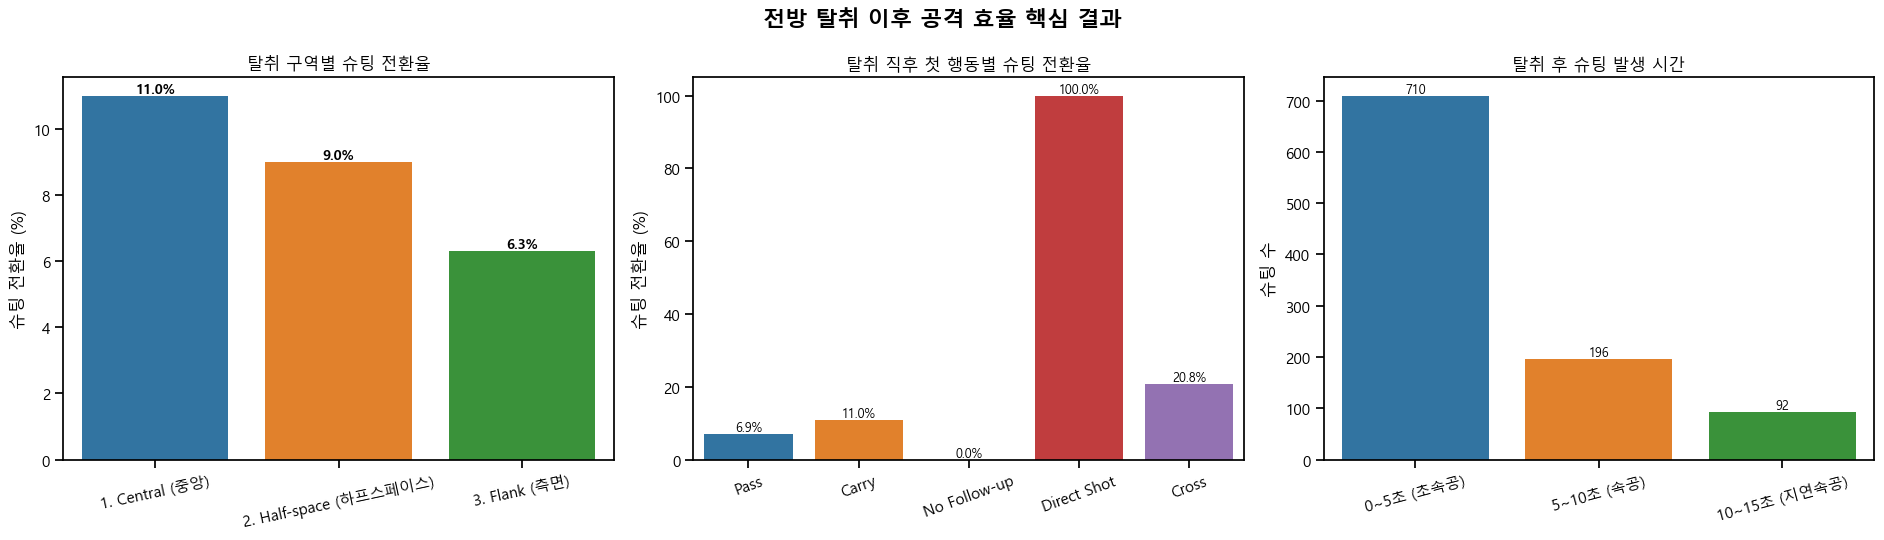

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

sns.barplot(
    data=zone_res,
    x="turnover_zone",
    y="슈팅전환율(%)",
    hue="turnover_zone",
    legend=False,
    ax=axes[0],
)
axes[0].set_title("탈취 구역별 슈팅 전환율")
axes[0].set_xlabel("")
axes[0].set_ylabel("슈팅 전환율 (%)")
axes[0].tick_params(axis="x", rotation=12)
for patch in axes[0].patches:
    axes[0].annotate(
        f"{patch.get_height():.1f}%",
        (patch.get_x() + patch.get_width() / 2, patch.get_height()),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

sns.barplot(
    data=action_res,
    x="first_action",
    y="슈팅전환율(%)",
    hue="first_action",
    legend=False,
    ax=axes[1],
)
axes[1].set_title("탈취 직후 첫 행동별 슈팅 전환율")
axes[1].set_xlabel("")
axes[1].set_ylabel("슈팅 전환율 (%)")
axes[1].tick_params(axis="x", rotation=20)
for patch in axes[1].patches:
    axes[1].annotate(
        f"{patch.get_height():.1f}%",
        (patch.get_x() + patch.get_width() / 2, patch.get_height()),
        ha="center",
        va="bottom",
        fontsize=9,
    )

sns.barplot(
    data=time_res,
    x="시간구간",
    y="슈팅수",
    hue="시간구간",
    legend=False,
    ax=axes[2],
)
axes[2].set_title("탈취 후 슈팅 발생 시간")
axes[2].set_xlabel("")
axes[2].set_ylabel("슈팅 수")
axes[2].tick_params(axis="x", rotation=15)
for patch in axes[2].patches:
    axes[2].annotate(
        f"{int(patch.get_height()):,}",
        (patch.get_x() + patch.get_width() / 2, patch.get_height()),
        ha="center",
        va="bottom",
        fontsize=9,
    )

fig.suptitle("전방 탈취 이후 공격 효율 핵심 결과", fontsize=16, fontweight="bold")
fig.tight_layout()
save_figure(fig, "01_core_results.png")
plt.show()



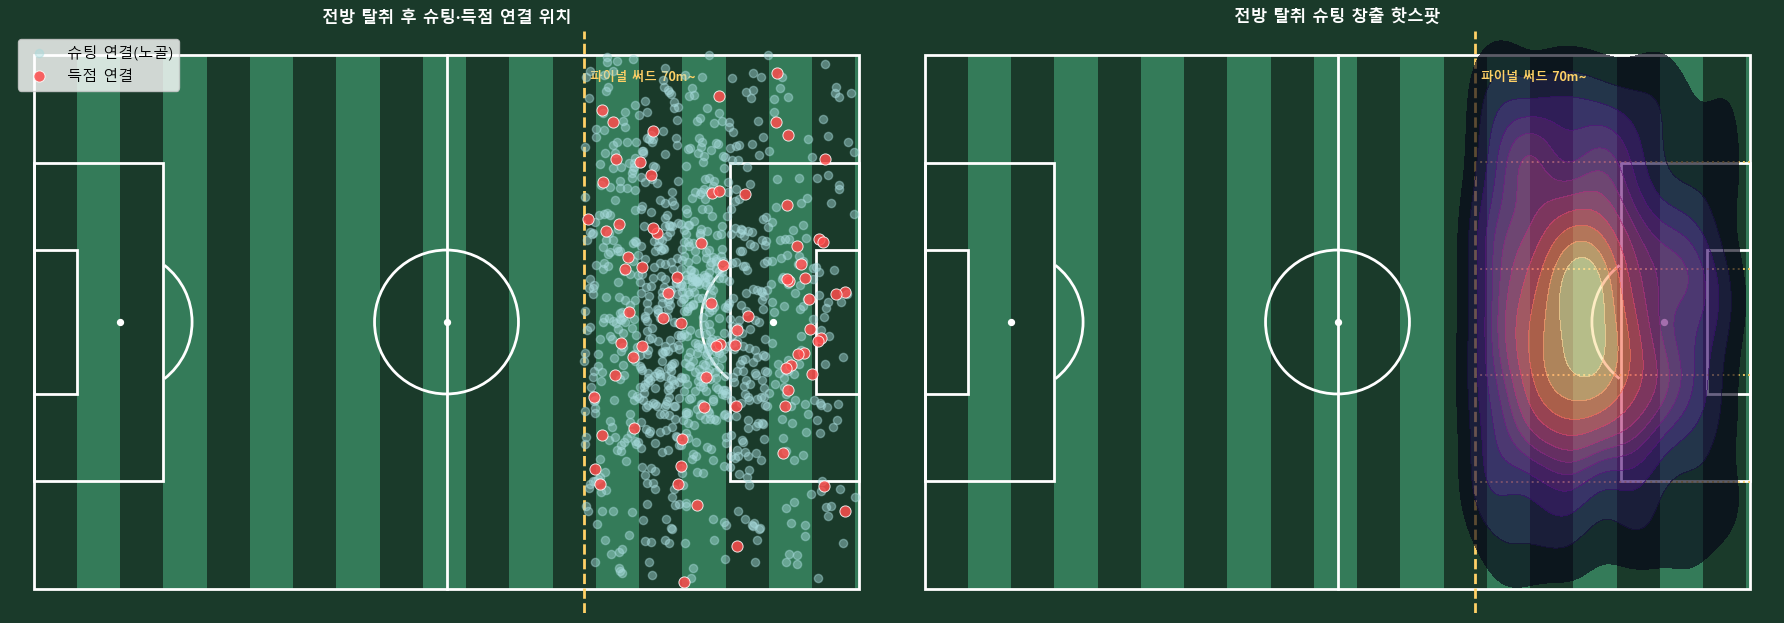

In [11]:
shot_turnovers = turnover_seq[turnover_seq["is_shot"].eq(1)].copy()
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.patch.set_facecolor("#1a3a2a")

# 실제 좌표 산점도
draw_pitch(axes[0], show_final_third=True, show_lanes=False)
no_goal = shot_turnovers[shot_turnovers["is_goal"].eq(0)]
goal = shot_turnovers[shot_turnovers["is_goal"].eq(1)]
axes[0].scatter(
    no_goal["turnover_x"],
    no_goal["turnover_y"],
    s=35,
    alpha=0.45,
    color="#a8dadc",
    label="슈팅 연결(노골)",
    zorder=3,
)
axes[0].scatter(
    goal["turnover_x"],
    goal["turnover_y"],
    s=65,
    alpha=0.85,
    color="#ff4d4d",
    edgecolor="white",
    linewidth=0.7,
    label="득점 연결",
    zorder=4,
)
axes[0].set_title("전방 탈취 후 슈팅·득점 연결 위치", color="white", fontweight="bold")
axes[0].legend(loc="upper left")

# 원본 좌표 기반 KDE
draw_pitch(axes[1], show_final_third=True, show_lanes=True)
if len(shot_turnovers) >= 10:
    sns.kdeplot(
        data=shot_turnovers,
        x="turnover_x",
        y="turnover_y",
        fill=True,
        cmap="magma",
        levels=12,
        thresh=0.05,
        alpha=0.65,
        ax=axes[1],
        zorder=2,
    )
else:
    axes[1].scatter(
        shot_turnovers["turnover_x"],
        shot_turnovers["turnover_y"],
        color="#ffd166",
        alpha=0.7,
    )
axes[1].set_title("전방 탈취 슈팅 창출 핫스팟", color="white", fontweight="bold")

fig.tight_layout()
save_figure(fig, "02_turnover_locations_and_kde.png")
plt.show()



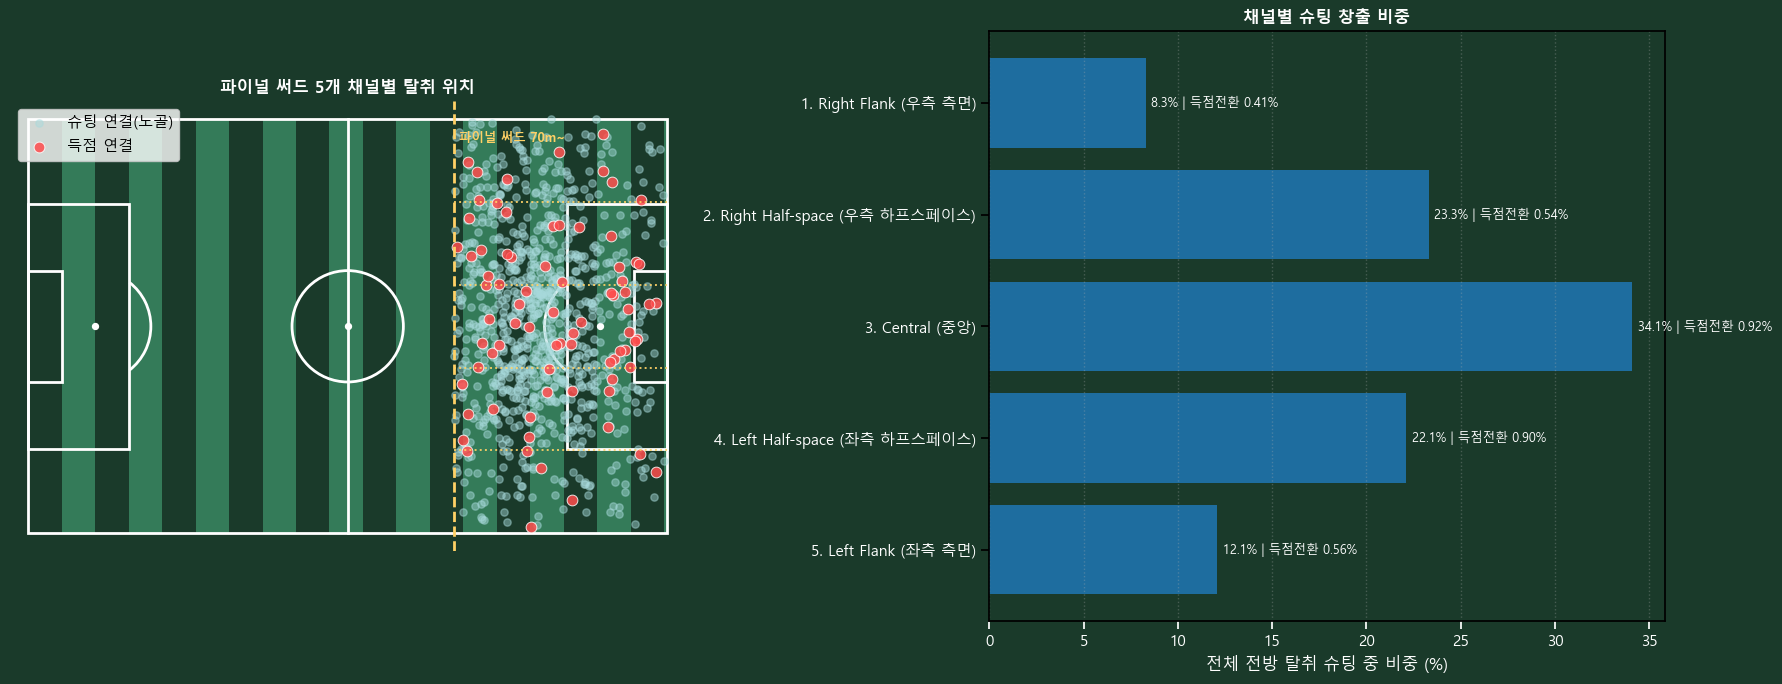

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.patch.set_facecolor("#1a3a2a")

draw_pitch(axes[0], show_final_third=True, show_lanes=True)
axes[0].scatter(
    no_goal["turnover_x"],
    no_goal["turnover_y"],
    s=28,
    alpha=0.45,
    color="#a8dadc",
    label="슈팅 연결(노골)",
)
axes[0].scatter(
    goal["turnover_x"],
    goal["turnover_y"],
    s=60,
    alpha=0.85,
    color="#ff4d4d",
    edgecolor="white",
    linewidth=0.7,
    label="득점 연결",
)
axes[0].set_title("파이널 써드 5개 채널별 탈취 위치", color="white", fontweight="bold")
axes[0].legend(loc="upper left")

plot_lane = lane_res.copy()
y = np.arange(len(plot_lane))
axes[1].set_facecolor("#1a3a2a")
bars = axes[1].barh(y, plot_lane["슈팅창출비중(%)"], alpha=0.85)
axes[1].set_yticks(y)
axes[1].set_yticklabels(plot_lane["turnover_lane"], color="white")
axes[1].set_xlabel("전체 전방 탈취 슈팅 중 비중 (%)", color="white")
axes[1].tick_params(axis="x", colors="white")
axes[1].set_title("채널별 슈팅 창출 비중", color="white", fontweight="bold")
axes[1].grid(axis="x", linestyle=":", alpha=0.3)
for bar, rate in zip(bars, plot_lane["득점전환율(%)"]):
    axes[1].text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}% | 득점전환 {rate:.2f}%",
        va="center",
        color="white",
        fontsize=9,
    )

fig.tight_layout()
save_figure(fig, "03_five_lane_analysis.png")
plt.show()



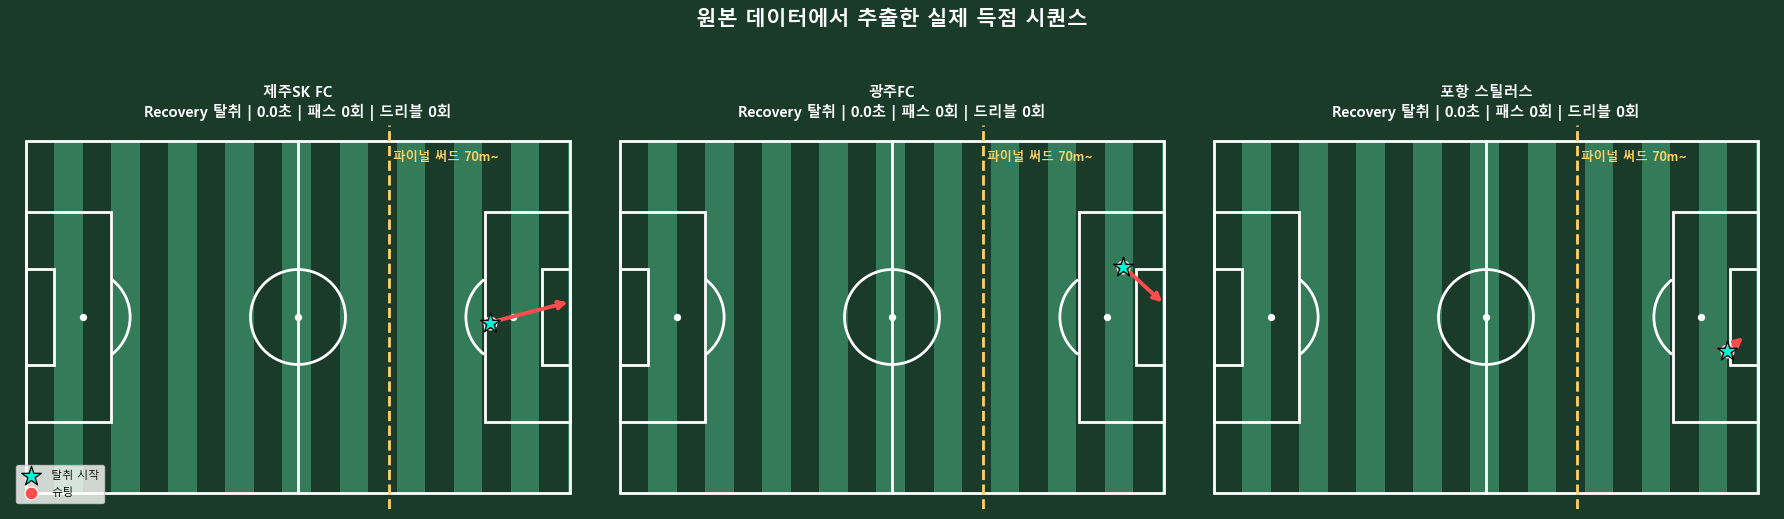

In [13]:

def plot_sequence_route(
    ax: plt.Axes,
    sequence_row: pd.Series,
    data: pd.DataFrame,
    title_prefix: str = "",
) -> None:
    draw_pitch(ax, show_final_third=True, show_lanes=False)

    turnover_idx = int(sequence_row["turnover_idx"])
    start = data.loc[turnover_idx]
    ax.scatter(
        start["norm_start_x"],
        start["norm_start_y"],
        marker="*",
        s=220,
        color="#00f5d4",
        edgecolor="black",
        linewidth=0.9,
        zorder=8,
        label="탈취 시작",
    )

    for idx in sequence_row["attacking_event_indices"]:
        row = data.loc[int(idx)]
        action = map_attack_action(row["event_key"])
        x1, y1 = row["norm_start_x"], row["norm_start_y"]
        x2, y2 = row["norm_end_x"], row["norm_end_y"]

        if action in {"Pass", "Pass Received", "Cross"}:
            color = "#00b4d8" if action != "Cross" else "#9b5de5"
            ax.annotate(
                "",
                xy=(x2, y2),
                xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", color=color, lw=2.2),
                zorder=5,
            )
        elif action == "Carry":
            ax.plot(
                [x1, x2],
                [y1, y2],
                color="#ffb703",
                linestyle="--",
                linewidth=2.3,
                zorder=5,
            )
        elif action == "Shot":
            shot_end_x = x2 if pd.notna(x2) else PITCH_LENGTH
            shot_end_y = y2 if pd.notna(y2) else PITCH_WIDTH / 2
            ax.annotate(
                "",
                xy=(shot_end_x, shot_end_y),
                xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", color="#ff4d4d", lw=2.8),
                zorder=6,
            )
            ax.scatter(
                x1,
                y1,
                s=85,
                color="#ff4d4d",
                edgecolor="white",
                linewidth=0.8,
                zorder=7,
                label="슈팅",
            )

    title = (
        f"{title_prefix}{sequence_row['team_name']}\n"
        f"{sequence_row['turnover_type']} 탈취 | "
        f"{sequence_row['time_to_shot']:.1f}초 | "
        f"패스 {sequence_row['pass_count']}회 | "
        f"드리블 {sequence_row['carry_count']}회"
    )
    ax.set_title(title, color="white", fontsize=10.5, fontweight="bold")


valid_goal_routes = turnover_seq[
    turnover_seq["is_goal"].eq(1)
    & turnover_seq["action_count"].between(1, 8)
    & turnover_seq["time_to_shot"].notna()
].sort_values(["time_to_shot", "action_count"])

if not valid_goal_routes.empty:
    examples = valid_goal_routes.head(3)
    fig, axes = plt.subplots(1, len(examples), figsize=(6 * len(examples), 6))
    fig.patch.set_facecolor("#1a3a2a")
    axes = np.atleast_1d(axes)
    for ax, (_, row) in zip(axes, examples.iterrows()):
        plot_sequence_route(ax, row, KLeague)
    axes[0].legend(loc="lower left", fontsize=8)
    fig.suptitle("원본 데이터에서 추출한 실제 득점 시퀀스", color="white", fontsize=15, fontweight="bold")
    fig.tight_layout()
    save_figure(fig, "04_actual_goal_sequences.png")
    plt.show()
else:
    print("[안내] 조건에 맞는 실제 득점 시퀀스가 없어 득점 경로 그림을 생략합니다.")



In [14]:
# 검증 결과: 소유권 기반 추정치와 중복 득점 연결 확인
print("\n[QA] 소유권 기반 전방 탈취:", int(KLeague["is_valid_high_turnover"].sum()))
print("[QA] 15초 이내 슈팅 시퀀스:", int(turnover_seq["is_shot"].sum()))
print("[QA] 15초 이내 득점 시퀀스:", int(turnover_seq["is_goal"].sum()))
print("[QA] 행동 1~8개 득점 경로:", len(valid_goal_routes))

def last_attack_event(items):
    return items[-1] if isinstance(items, list) and items else np.nan

goal_sequences_qa = turnover_seq.loc[turnover_seq["is_goal"].eq(1)].copy()
goal_sequences_qa["last_shot_event_index"] = goal_sequences_qa["attacking_event_indices"].map(last_attack_event)
goal_sequences_qa["duplicate_shot_link"] = goal_sequences_qa.duplicated(
    ["game_id", "period_id", "last_shot_event_index"], keep=False)
print("[QA] 같은 슈팅에 연결된 시퀀스:", int(goal_sequences_qa["duplicate_shot_link"].sum()))
goal_sequences_qa.to_csv(OUTPUT_DIR / "11_goal_sequence_audit.csv", index=False, encoding="utf-8-sig")



[QA] 소유권 기반 전방 탈취: 11018
[QA] 15초 이내 슈팅 시퀀스: 998
[QA] 15초 이내 득점 시퀀스: 78
[QA] 행동 1~8개 득점 경로: 70
[QA] 같은 슈팅에 연결된 시퀀스: 0


In [15]:
# 여기서 team_id 변경은 '전방 탈취 판정'이 아니라 전체 소유 시퀀스를 나누는 경계로만 사용합니다.

def build_all_possessions(data: pd.DataFrame) -> pd.DataFrame:
    """추정 실질 공 통제 팀을 기준으로 소유 시퀀스를 구성합니다.

    블록 등 비통제 수비 이벤트는 현재 소유팀을 변경하지 않습니다.
    소유권 미확인 구간은 분모에서 제외합니다.
    """
    df = data.copy()
    owner = df["controlled_possession_team_id"]
    game_change = df["game_id"].ne(df["game_id"].shift(1))
    period_change = df["period_id"].ne(df["period_id"].shift(1))
    owner_change = owner.ne(owner.shift(1))
    previous_stoppage = df["event_key"].shift(1).fillna("").map(is_stoppage_event)
    possession_break = game_change | period_change | owner_change | previous_stoppage
    df["possession_id"] = possession_break.cumsum()
    df = df[owner.notna()].copy()
    df["owner_team_id"] = owner[owner.notna()]
    # 팀 이름은 해당 소유팀의 이벤트 기록에서 매핑합니다.
    team_names = (data.drop_duplicates("team_id")
                  .set_index("team_id")["team_name_ko"].to_dict())
    possessions = (
        df.groupby("possession_id", as_index=False)
        .agg(game_id=("game_id", "first"),
             period_id=("period_id", "first"),
             team_id=("owner_team_id", "first"),
             start_time=("time_seconds", "min"),
             end_time=("time_seconds", "max"),
             event_count=("event_index", "size"))
    )
    possessions["team_name"] = possessions["team_id"].map(team_names)
    possessions["duration"] = possessions["end_time"] - possessions["start_time"]
    return possessions


all_possessions = build_all_possessions(KLeague)

team_turnover_summary = (
    turnover_seq.groupby(["team_id", "team_name"], as_index=False)
    .agg(
        전방탈취수=("turnover_idx", "size"),
        슈팅창출수=("is_shot", "sum"),
        득점수=("is_goal", "sum"),
        평균탈취X=("turnover_x", "mean"),
        평균전진거리_m=("positive_progress_m", "mean"),
        평균전개시간_초=("sequence_duration", "mean"),
        평균전개속도_mps=("progress_speed_mps", "mean"),
        중앙탈취비중=("turnover_zone", lambda x: (x == "1. Central (중앙)").mean()),
        하프스페이스탈취비중=(
            "turnover_zone",
            lambda x: (x == "2. Half-space (하프스페이스)").mean(),
        ),
        측면탈취비중=("turnover_zone", lambda x: (x == "3. Flank (측면)").mean()),
        드리블활용비중=("has_carry", "mean"),
        오초이내슈팅비중=(
            "time_to_shot",
            lambda x: ((x <= 5) & x.notna()).mean(),
        ),
    )
)

possession_counts = (
    all_possessions.groupby(["team_id", "team_name"], as_index=False)
    .agg(전체소유시퀀스수=("possession_id", "nunique"))
)

team_summary = possession_counts.merge(
    team_turnover_summary, on=["team_id", "team_name"], how="left"
)
count_cols = ["전방탈취수", "슈팅창출수", "득점수"]
team_summary[count_cols] = team_summary[count_cols].fillna(0).astype(int)

team_summary["전방탈취비중(%)"] = (
    team_summary["전방탈취수"] / team_summary["전체소유시퀀스수"] * 100
).round(2)
team_summary["슈팅전환율(%)"] = np.where(
    team_summary["전방탈취수"] > 0,
    team_summary["슈팅창출수"] / team_summary["전방탈취수"] * 100,
    np.nan,
)
team_summary["득점전환율(%)"] = np.where(
    team_summary["전방탈취수"] > 0,
    team_summary["득점수"] / team_summary["전방탈취수"] * 100,
    np.nan,
)
team_summary["슈팅대비득점률(%)"] = np.where(
    team_summary["슈팅창출수"] > 0,
    team_summary["득점수"] / team_summary["슈팅창출수"] * 100,
    np.nan,
)

share_cols = [
    "중앙탈취비중",
    "하프스페이스탈취비중",
    "측면탈취비중",
    "드리블활용비중",
    "오초이내슈팅비중",
]
for col in share_cols:
    team_summary[col.replace("비중", "비중(%)")] = team_summary[col] * 100

round_cols = [
    "평균탈취X",
    "평균전진거리_m",
    "평균전개시간_초",
    "평균전개속도_mps",
    "슈팅전환율(%)",
    "득점전환율(%)",
    "슈팅대비득점률(%)",
    "중앙탈취비중(%)",
    "하프스페이스탈취비중(%)",
    "측면탈취비중(%)",
    "드리블활용비중(%)",
    "오초이내슈팅비중(%)",
]
team_summary[round_cols] = team_summary[round_cols].round(2)

# Z-score는 실제 팀별 전방 탈취 비중으로 계산합니다.
ratio_mean = team_summary["전방탈취비중(%)"].mean()
ratio_std = team_summary["전방탈취비중(%)"].std(ddof=0)
team_summary["전방탈취비중_Z"] = np.where(
    ratio_std > 0,
    (team_summary["전방탈취비중(%)"] - ratio_mean) / ratio_std,
    0,
)
team_summary["전방탈취비중_Z"] = team_summary["전방탈취비중_Z"].round(3)
team_summary = team_summary.sort_values("전방탈취비중(%)", ascending=False).reset_index(drop=True)

print("\n--- [13] 팀별 전방 압박 효율 ---")
print(
    team_summary[
        [
            "team_name",
            "전체소유시퀀스수",
            "전방탈취수",
            "전방탈취비중(%)",
            "슈팅창출수",
            "슈팅전환율(%)",
            "득점수",
            "득점전환율(%)",
            "평균전개속도_mps",
        ]
    ].to_string(index=False)
)
team_summary.to_csv(
    OUTPUT_DIR / "09_team_summary.csv", index=False, encoding="utf-8-sig"
)
all_possessions.to_csv(
    OUTPUT_DIR / "10_all_possession_sequences.csv", index=False, encoding="utf-8-sig"
)




--- [13] 팀별 전방 압박 효율 ---
  team_name  전체소유시퀀스수  전방탈취수  전방탈취비중(%)  슈팅창출수  슈팅전환율(%)  득점수  득점전환율(%)  평균전개속도_mps
  대전 하나 시티즌      5052   1208      23.91     55      4.55    3      0.25       34.34
  전북 현대 모터스      4898    980      20.01     85      8.67    6      0.61       89.39
    포항 스틸러스      4743    947      19.97     90      9.50    7      0.74       68.31
       FC서울      4958    976      19.69     75      7.68    5      0.51       95.61
       광주FC      4770    881      18.47     80      9.08    5      0.57      133.05
   인천 유나이티드      5066    932      18.40     80      8.58    5      0.54      124.90
김천 상무 프로축구단      5138    941      18.31     90      9.56    9      0.96      103.80
       대구FC      5127    919      17.92     66      7.18    6      0.65      103.08
       수원FC      4904    862      17.58    105     12.18    8      0.93      142.78
    제주SK FC      5461    877      16.06    103     11.74    7      0.80      140.82
       강원FC      4730    757      16.00     85    

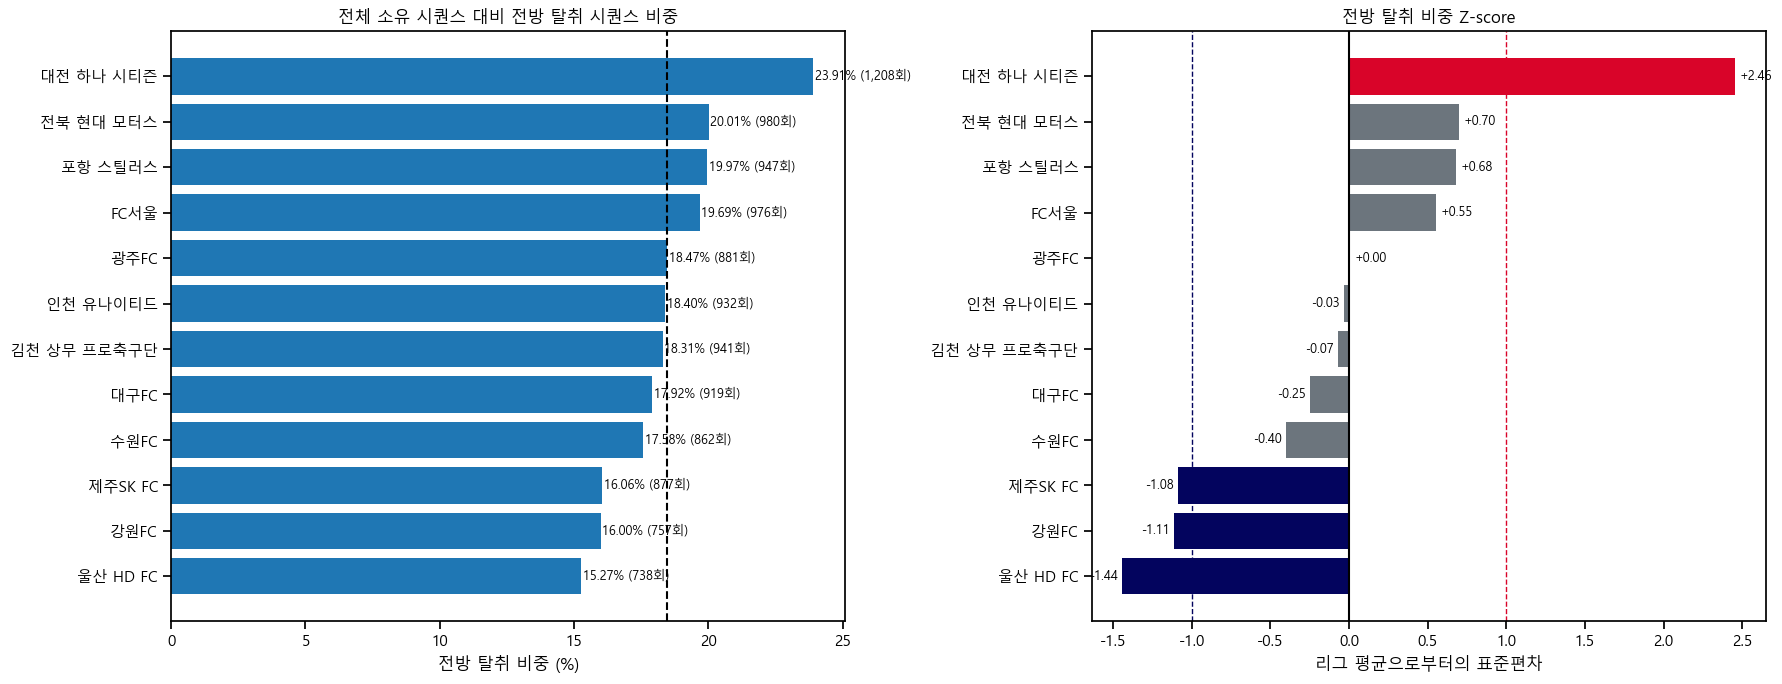

In [16]:
plot_team = team_summary.sort_values("전방탈취비중(%)", ascending=True)
fig, axes = plt.subplots(1, 2, figsize=(18, max(7, len(plot_team) * 0.55)))

bars = axes[0].barh(plot_team["team_name"], plot_team["전방탈취비중(%)"])
axes[0].axvline(ratio_mean, linestyle="--", color="black", linewidth=1.5)
axes[0].set_title("전체 소유 시퀀스 대비 전방 탈취 시퀀스 비중")
axes[0].set_xlabel("전방 탈취 비중 (%)")
for bar, count in zip(bars, plot_team["전방탈취수"]):
    axes[0].text(
        bar.get_width() + 0.05,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}% ({count:,}회)",
        va="center",
        fontsize=9,
    )

z_colors = ["#d90429" if z >= 1 else "#03045e" if z <= -1 else "#6c757d" for z in plot_team["전방탈취비중_Z"]]
z_bars = axes[1].barh(
    plot_team["team_name"], plot_team["전방탈취비중_Z"], color=z_colors
)
axes[1].axvline(0, color="black", linewidth=1.5)
axes[1].axvline(1, color="#d90429", linestyle="--", linewidth=1)
axes[1].axvline(-1, color="#03045e", linestyle="--", linewidth=1)
axes[1].set_title("전방 탈취 비중 Z-score")
axes[1].set_xlabel("리그 평균으로부터의 표준편차")
for bar in z_bars:
    value = bar.get_width()
    axes[1].text(
        value + (0.03 if value >= 0 else -0.03),
        bar.get_y() + bar.get_height() / 2,
        f"{value:+.2f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=9,
    )

fig.tight_layout()
save_figure(fig, "05_team_high_press_share_and_zscore.png")
plt.show()



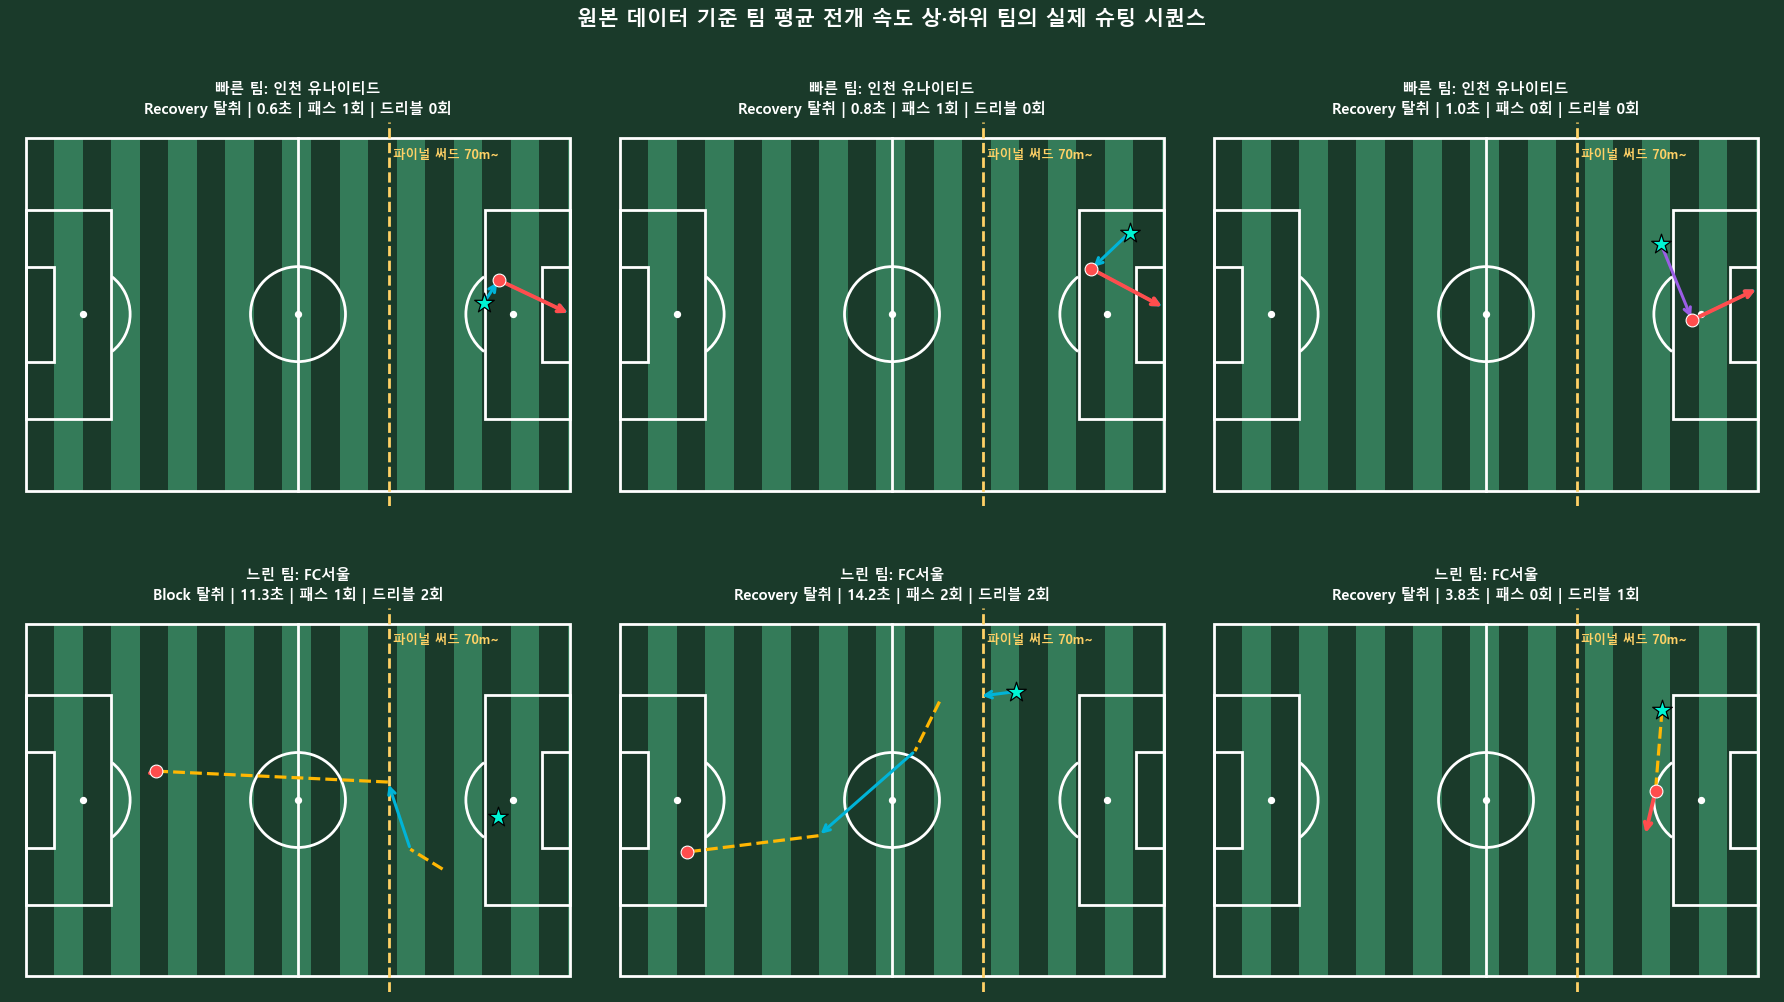

In [17]:
eligible_speed = (
    turnover_seq[
        turnover_seq["is_shot"].eq(1)
        & turnover_seq["progress_speed_mps"].notna()
        & turnover_seq["sequence_duration"].gt(0)
    ]
    .groupby("team_name")
    .agg(
        평균전개속도=("progress_speed_mps", "mean"),
        유효시퀀스수=("turnover_idx", "size"),
    )
)
eligible_speed = eligible_speed[eligible_speed["유효시퀀스수"] >= 3]

if len(eligible_speed) >= 2:
    fastest_team = eligible_speed["평균전개속도"].idxmax()
    slowest_team = eligible_speed["평균전개속도"].idxmin()
    selected_teams = [fastest_team, slowest_team]

    fig, axes = plt.subplots(2, 3, figsize=(18, 11))
    fig.patch.set_facecolor("#1a3a2a")

    for row_idx, team in enumerate(selected_teams):
        team_sequences = turnover_seq[
            turnover_seq["team_name"].eq(team)
            & turnover_seq["is_shot"].eq(1)
            & turnover_seq["progress_speed_mps"].notna()
        ].copy()
        if row_idx == 0:
            team_sequences = team_sequences.sort_values("progress_speed_mps", ascending=False)
        else:
            team_sequences = team_sequences.sort_values("progress_speed_mps", ascending=True)
        examples = team_sequences.head(3)

        for col_idx, ax in enumerate(axes[row_idx]):
            if col_idx < len(examples):
                row = examples.iloc[col_idx]
                prefix = "빠른 팀: " if row_idx == 0 else "느린 팀: "
                plot_sequence_route(ax, row, KLeague, title_prefix=prefix)
            else:
                ax.axis("off")

    fig.suptitle(
        "원본 데이터 기준 팀 평균 전개 속도 상·하위 팀의 실제 슈팅 시퀀스",
        color="white",
        fontsize=15,
        fontweight="bold",
    )
    fig.tight_layout()
    save_figure(fig, "06_fastest_vs_slowest_team_sequences.png")
    plt.show()
else:
    print("[안내] 팀별 속도 비교에 필요한 유효 슈팅 시퀀스가 부족해 그림을 생략합니다.")



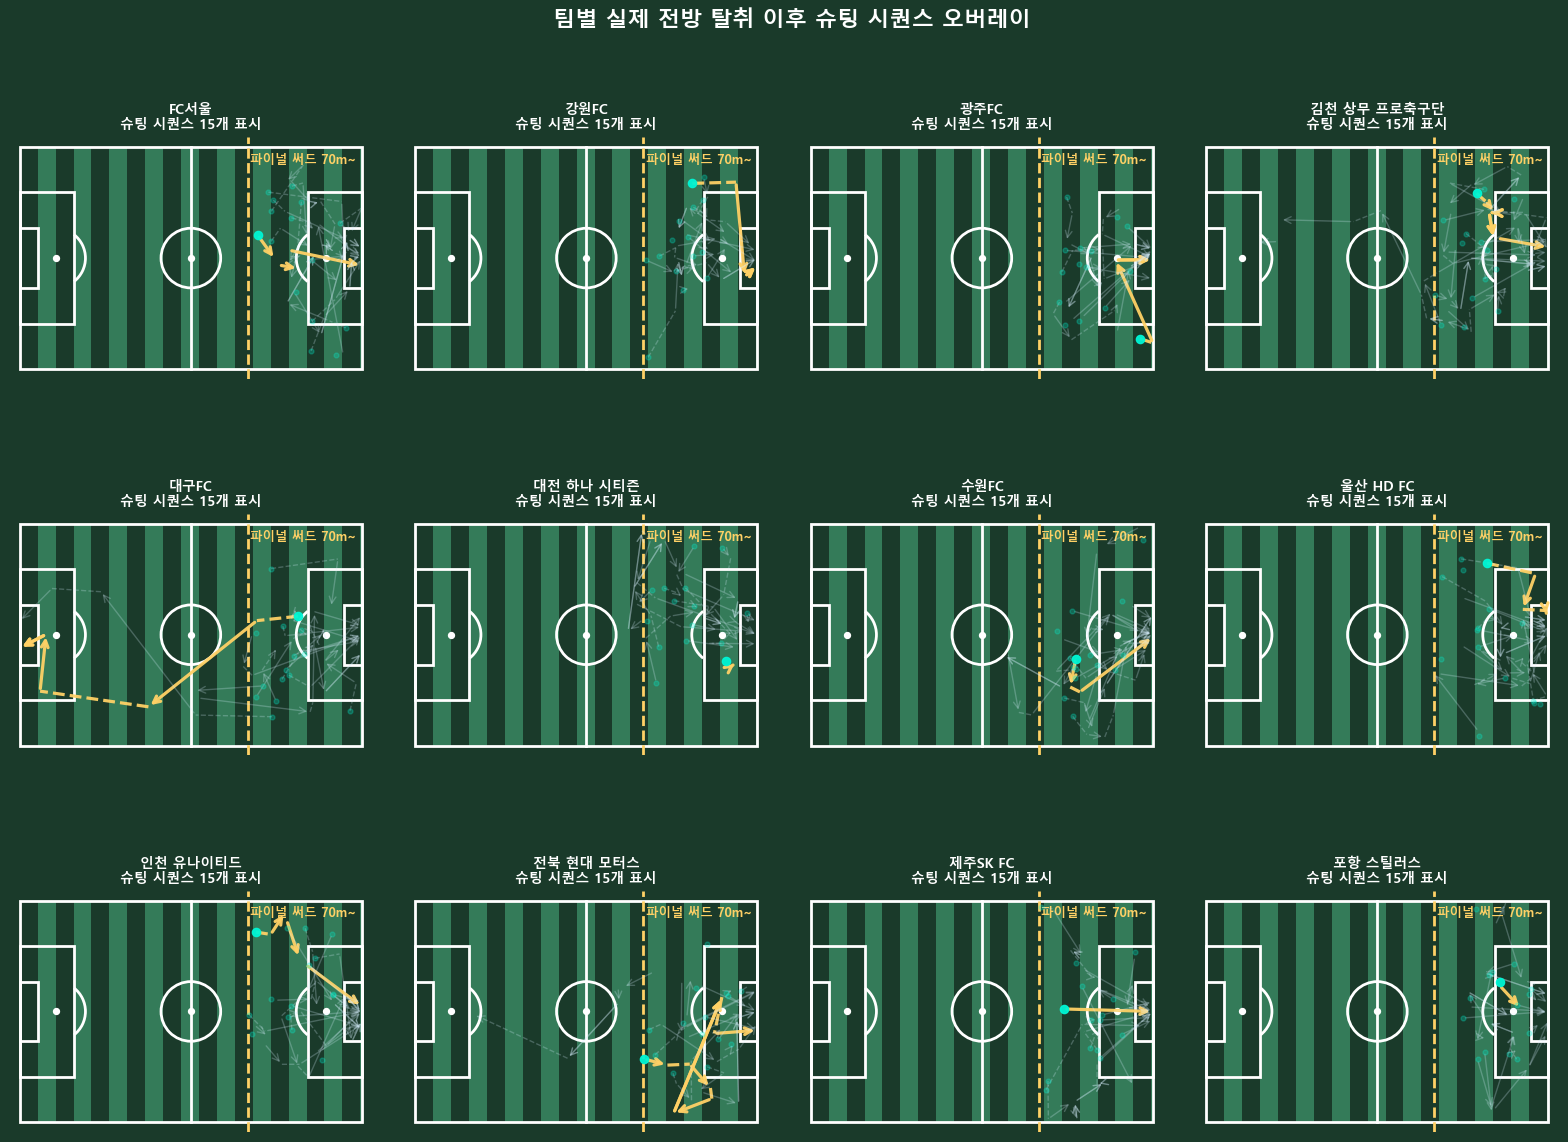

In [18]:
teams = sorted(turnover_seq["team_name"].dropna().unique().tolist())
if teams:
    ncols = 4
    nrows = math.ceil(len(teams) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, nrows * 4.2))
    fig.patch.set_facecolor("#1a3a2a")
    axes = np.atleast_1d(axes).flatten()

    for ax, team in zip(axes, teams):
        draw_pitch(ax, show_final_third=True, show_lanes=False)
        team_seq = turnover_seq[
            turnover_seq["team_name"].eq(team) & turnover_seq["is_shot"].eq(1)
        ].copy()
        # 임의 추출이 아니라 시간 순서상 앞선 실제 시퀀스 최대 15개를 사용합니다.
        team_seq = team_seq.sort_values(["game_id", "period_id", "turnover_time"]).head(15)

        for seq_idx, (_, seq_row) in enumerate(team_seq.iterrows()):
            highlight = seq_idx == 0
            alpha = 0.95 if highlight else 0.25
            linewidth = 2.3 if highlight else 1.0
            color = "#ffd166" if highlight else "#d9f0ff"

            for event_idx in seq_row["attacking_event_indices"]:
                event = KLeague.loc[int(event_idx)]
                action = map_attack_action(event["event_key"])
                if action is None:
                    continue
                x1, y1 = event["norm_start_x"], event["norm_start_y"]
                x2, y2 = event["norm_end_x"], event["norm_end_y"]
                if action == "Carry":
                    ax.plot(
                        [x1, x2],
                        [y1, y2],
                        color=color,
                        linestyle="--",
                        linewidth=linewidth,
                        alpha=alpha,
                        zorder=4,
                    )
                else:
                    ax.annotate(
                        "",
                        xy=(x2, y2),
                        xytext=(x1, y1),
                        arrowprops=dict(
                            arrowstyle="->",
                            color=color,
                            lw=linewidth,
                            alpha=alpha,
                        ),
                        zorder=4,
                    )

            ax.scatter(
                seq_row["turnover_x"],
                seq_row["turnover_y"],
                s=35 if highlight else 12,
                color="#00f5d4",
                alpha=alpha,
                zorder=5,
            )

        ax.set_title(
            f"{team}\n슈팅 시퀀스 {len(team_seq)}개 표시",
            color="white",
            fontsize=10,
            fontweight="bold",
        )

    for ax in axes[len(teams) :]:
        ax.axis("off")

    fig.suptitle(
        "팀별 실제 전방 탈취 이후 슈팅 시퀀스 오버레이",
        color="white",
        fontsize=16,
        fontweight="bold",
    )
    fig.tight_layout()
    save_figure(fig, "07_all_team_sequence_overlays.png")
    plt.show()



In [19]:

def normalize_team_key(name: object) -> str:
    if pd.isna(name):
        return ""
    text = str(name).strip().lower()
    text = re.sub(r"\s+", "", text)
    text = text.replace("프로축구단", "")
    text = text.replace("footballclub", "")
    return text


def find_column(columns: Iterable[str], candidates: Iterable[str]) -> Optional[str]:
    normalized = {normalize_text(col): col for col in columns}
    for candidate in candidates:
        key = normalize_text(candidate)
        if key in normalized:
            return normalized[key]
    return None


if RANK_PATH.exists():
    rank_raw = pd.read_excel(RANK_PATH)
    rank_team_col = find_column(
        rank_raw.columns,
        ["team", "team_name", "team_name_ko", "팀", "팀명", "구단", "구단명"],
    )
    rank_col = find_column(rank_raw.columns, ["rank", "순위", "ranking"])

    if rank_team_col is None or rank_col is None:
        print(
            "[안내] 순위 파일에서 팀명 또는 순위 컬럼을 자동으로 찾지 못해 상관분석을 생략합니다."
        )
    else:
        rank_df = rank_raw[[rank_team_col, rank_col]].copy()
        rank_df.columns = ["rank_team_name", "Rank"]
        rank_df["Rank"] = pd.to_numeric(rank_df["Rank"], errors="coerce")
        rank_df = rank_df.dropna(subset=["Rank"])

        alias_normalized = {
            normalize_team_key(key): normalize_team_key(value)
            for key, value in TEAM_NAME_ALIASES.items()
        }
        team_summary["team_key"] = team_summary["team_name"].map(normalize_team_key)
        team_summary["team_key"] = team_summary["team_key"].replace(alias_normalized)
        rank_df["team_key"] = rank_df["rank_team_name"].map(normalize_team_key)

        rank_merged = team_summary.merge(rank_df, on="team_key", how="left")
        unmatched = rank_merged.loc[rank_merged["Rank"].isna(), "team_name"].tolist()
        if unmatched:
            print("[안내] 순위 파일과 매칭되지 않은 팀:", unmatched)

        rank_merged = rank_merged.dropna(subset=["Rank"]).copy()
        metric_columns = [
            "Rank",
            "평균탈취X",
            "슈팅전환율(%)",
            "득점전환율(%)",
            "평균전개속도_mps",
            "중앙탈취비중(%)",
            "하프스페이스탈취비중(%)",
            "측면탈취비중(%)",
            "전방탈취비중(%)",
        ]
        metric_columns = [col for col in metric_columns if col in rank_merged.columns]

        if len(rank_merged) >= 4:
            spearman_corr = rank_merged[metric_columns].corr(method="spearman")
            print("\n--- [17] 실제 순위와 팀별 전방 압박 지표의 스피어만 상관계수 ---")
            print(spearman_corr.round(3).to_string())

            spearman_corr.to_csv(
                OUTPUT_DIR / "11_rank_spearman_correlation.csv",
                encoding="utf-8-sig",
            )
            rank_merged.to_csv(
                OUTPUT_DIR / "12_rank_merged_team_metrics.csv",
                index=False,
                encoding="utf-8-sig",
            )

            fig, ax = plt.subplots(figsize=(11, 9))
            sns.heatmap(
                spearman_corr,
                annot=True,
                fmt=".2f",
                cmap="coolwarm",
                vmin=-1,
                vmax=1,
                linewidths=0.6,
                ax=ax,
            )
            ax.set_title("실제 K리그 순위와 전방 압박 지표의 스피어만 상관분석")
            fig.tight_layout()
            save_figure(fig, "08_rank_spearman_heatmap.png")
            plt.show()
        else:
            print("[안내] 순위와 매칭된 팀이 4개 미만이라 상관분석을 생략합니다.")
else:
    print(
        f"[안내] {RANK_PATH.name} 파일이 없어 순위 상관분석을 생략합니다. "
        "순위 파일을 같은 폴더에 두면 자동 실행됩니다."
    )



[안내] 2024 K리그1 순위.xlsx 파일이 없어 순위 상관분석을 생략합니다. 순위 파일을 같은 폴더에 두면 자동 실행됩니다.


In [20]:
# 다른 조건을 함께 통제했을 때 탈취 구역·첫 행동·드리블 등이 슈팅 가능성과 관련되는지 확인합니다.
try:
    import statsmodels.formula.api as smf

    model_df = turnover_seq.copy()
    common_actions = model_df["first_action"].value_counts().head(4).index
    model_df["first_action_model"] = np.where(
        model_df["first_action"].isin(common_actions),
        model_df["first_action"],
        "Other",
    )
    model_df = model_df[
        [
            "is_shot",
            "turnover_zone",
            "first_action_model",
            "has_carry",
            "pass_count",
            "positive_progress_m",
            "turnover_x",
            "game_id",
        ]
    ].dropna()

    if model_df["is_shot"].nunique() == 2 and len(model_df) >= 100:
        formula = (
            "is_shot ~ C(turnover_zone) + C(first_action_model) + "
            "has_carry + pass_count + positive_progress_m + turnover_x"
        )
        logistic_model = smf.logit(formula=formula, data=model_df).fit(
            disp=False, maxiter=200
        )

        params = logistic_model.params
        conf = logistic_model.conf_int()
        odds_ratio_table = pd.DataFrame(
            {
                "변수": params.index,
                "오즈비": np.exp(params.values),
                "95%CI_하한": np.exp(conf[0].values),
                "95%CI_상한": np.exp(conf[1].values),
                "p값": logistic_model.pvalues.values,
            }
        )
        odds_ratio_table[["오즈비", "95%CI_하한", "95%CI_상한", "p값"]] = (
            odds_ratio_table[["오즈비", "95%CI_하한", "95%CI_상한", "p값"]].round(4)
        )

        print("\n--- [18] 슈팅 발생 로지스틱 회귀 오즈비 ---")
        print(odds_ratio_table.to_string(index=False))
        odds_ratio_table.to_csv(
            OUTPUT_DIR / "13_logistic_regression_odds_ratios.csv",
            index=False,
            encoding="utf-8-sig",
        )
    else:
        print("[안내] 로지스틱 회귀에 필요한 표본 또는 결과 변이가 부족합니다.")
except ImportError:
    print("[안내] statsmodels가 설치되지 않아 로지스틱 회귀를 생략합니다.")
except Exception as error:
    print(f"[안내] 로지스틱 회귀를 완료하지 못했습니다: {error}")




--- [18] 슈팅 발생 로지스틱 회귀 오즈비 ---
                                        변수          오즈비  95%CI_하한  95%CI_상한     p값
                                 Intercept 3.500000e-03    0.0012    0.0104 0.0000
C(turnover_zone)[T.2. Half-space (하프스페이스)] 7.087000e-01    0.5665    0.8865 0.0026
         C(turnover_zone)[T.3. Flank (측면)] 5.498000e-01    0.4427    0.6829 0.0000
      C(first_action_model)[T.Direct Shot] 3.043027e+10    0.0000       inf 0.9954
     C(first_action_model)[T.No Follow-up] 0.000000e+00    0.0000       inf 1.0000
            C(first_action_model)[T.Other] 1.817600e+00    1.0063    3.2828 0.0476
             C(first_action_model)[T.Pass] 1.734700e+00    1.3539    2.2227 0.0000
                                 has_carry 2.094200e+00    1.5692    2.7949 0.0000
                                pass_count 3.382000e-01    0.3069    0.3727 0.0000
                       positive_progress_m 1.119700e+00    1.1106    1.1288 0.0000
                                turnover_x 1.033200e+00

c:\Users\USER\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\USER\AppData\Local\Temp\ipykernel_29664\2712790311.py:41: RuntimeWarning: overflow encountered in exp
  "95%CI_상한": np.exp(conf[1].values),


In [21]:
print("\n" + "=" * 88)
print("분석 완료")
print(f"결과 저장 폴더: {OUTPUT_DIR.resolve()}")
for file_path in sorted(OUTPUT_DIR.glob("*")):
    print("-", file_path.name)
print("=" * 88)



분석 완료
결과 저장 폴더: C:\Users\USER\Downloads\high_press_outputs
- 00_defensive_event_name_check.csv
- 01_core_results.png
- 01_high_press_turnover_sequences.csv
- 02_overall_summary.csv
- 02_turnover_locations_and_kde.png
- 03_five_lane_analysis.png
- 03_zone_results.csv
- 04_actual_goal_sequences.png
- 04_turnover_type_results.csv
- 05_first_action_results.csv
- 05_team_high_press_share_and_zscore.png
- 06_carry_results.csv
- 06_fastest_vs_slowest_team_sequences.png
- 07_all_team_sequence_overlays.png
- 07_time_results.csv
- 08_five_lane_results.csv
- 09_team_summary.csv
- 10_all_possession_sequences.csv
- 11_goal_sequence_audit.csv
- 13_logistic_regression_odds_ratios.csv


In [22]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


TEAM_VIS_DIR = OUTPUT_DIR / "team_sequence_visuals"
TEAM_VIS_DIR.mkdir(parents=True, exist_ok=True)


def save_figure_to(fig: plt.Figure, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(
        path,
        dpi=180,
        bbox_inches="tight",
        facecolor=fig.get_facecolor(),
    )


def team_file_safe(name: str) -> str:
    text = str(name).strip()
    text = re.sub(r'[\\/:*?"<>|]+', "_", text)
    text = re.sub(r"\s+", "_", text)
    return text


def get_sequence_result_label(seq_row: pd.Series) -> str:
    return "Goal" if int(seq_row["is_goal"]) == 1 else "Shot"


def plot_sequence_route_detailed(
    ax: plt.Axes,
    sequence_row: pd.Series,
    data: pd.DataFrame,
    title_prefix: str = "",
) -> None:
    """
    개별 시퀀스를 보기 좋게 그리는 함수.
    패스/크로스/드리블/슈팅을 색으로 구분하고,
    탈취 시작점과 슈팅 결과를 제목에 함께 표시합니다.
    """
    draw_pitch(ax, show_final_third=True, show_lanes=False)

    turnover_idx = int(sequence_row["turnover_idx"])
    start = data.loc[turnover_idx]

    # 탈취 시작점
    ax.scatter(
        start["norm_start_x"],
        start["norm_start_y"],
        marker="*",
        s=220,
        color="#00f5d4",
        edgecolor="black",
        linewidth=1.0,
        zorder=8,
        label="탈취 시작",
    )

    # 패널 배경 효과용
    ax.set_facecolor("#1a3a2a")

    # 행동 색상
    action_color = {
        "Pass": "#4cc9f0",
        "Pass Received": "#90e0ef",
        "Cross": "#9b5de5",
        "Carry": "#ffb703",
        "Shot": "#ff4d4d",
    }

    shot_plotted = False

    for event_idx in sequence_row["attacking_event_indices"]:
        row = data.loc[int(event_idx)]
        action = map_attack_action(row["event_key"])
        if action is None:
            continue

        x1, y1 = row["norm_start_x"], row["norm_start_y"]
        x2, y2 = row["norm_end_x"], row["norm_end_y"]

        if action in {"Pass", "Pass Received", "Cross"}:
            ax.annotate(
                "",
                xy=(x2, y2),
                xytext=(x1, y1),
                arrowprops=dict(
                    arrowstyle="->",
                    color=action_color[action],
                    lw=2.2 if action != "Cross" else 2.5,
                    alpha=0.95,
                ),
                zorder=5,
            )

        elif action == "Carry":
            ax.plot(
                [x1, x2],
                [y1, y2],
                color=action_color[action],
                linestyle="--",
                linewidth=2.5,
                alpha=0.95,
                zorder=5,
            )

        elif action == "Shot":
            shot_end_x = x2 if pd.notna(x2) else PITCH_LENGTH
            shot_end_y = y2 if pd.notna(y2) else PITCH_WIDTH / 2

            ax.annotate(
                "",
                xy=(shot_end_x, shot_end_y),
                xytext=(x1, y1),
                arrowprops=dict(
                    arrowstyle="->",
                    color=action_color[action],
                    lw=3.0,
                    alpha=0.98,
                ),
                zorder=6,
            )

            ax.scatter(
                x1,
                y1,
                s=95,
                color="#ff4d4d",
                edgecolor="white",
                linewidth=0.8,
                zorder=7,
                label="슈팅" if not shot_plotted else None,
            )
            shot_plotted = True

    result_label = get_sequence_result_label(sequence_row)
    result_text = "득점" if result_label == "Goal" else "슈팅"
    title_color = "#ff4d4d" if result_label == "Goal" else "white"

    title = (
        f"{title_prefix}{sequence_row['team_name']} | {result_text}\n"
        f"게임 {sequence_row['game_id']} | 전반/후반 {sequence_row['period_id']} | "
        f"탈취유형 {sequence_row['turnover_type']}\n"
        f"시간 {sequence_row['turnover_time']:.1f}s | "
        f"슈팅까지 {sequence_row['time_to_shot']:.1f}s | "
        f"패스 {sequence_row['pass_count']} | 드리블 {sequence_row['carry_count']} | "
        f"크로스 {sequence_row['cross_count']}"
    )
    ax.set_title(title, color=title_color, fontsize=10, fontweight="bold")


def plot_team_overlay_all_sequences(
    team_name: str,
    team_sequences: pd.DataFrame,
    data: pd.DataFrame,
    filename: Path,
) -> None:
    """
    팀별 전체 슈팅/득점 시퀀스를 한 장에 오버레이.
    - 일반 슈팅: 연한 파란색
    - 득점: 빨간색 강조
    """
    fig, ax = plt.subplots(figsize=(11, 7))
    fig.patch.set_facecolor("#1a3a2a")
    draw_pitch(ax, show_final_third=True, show_lanes=False)

    for _, seq_row in team_sequences.iterrows():
        is_goal = int(seq_row["is_goal"]) == 1
        base_color = "#ff4d4d" if is_goal else "#bde0fe"
        alpha = 0.85 if is_goal else 0.18
        lw = 2.4 if is_goal else 1.0

        # 시작점
        ax.scatter(
            seq_row["turnover_x"],
            seq_row["turnover_y"],
            s=42 if is_goal else 18,
            color="#00f5d4" if not is_goal else "#ffd166",
            alpha=alpha,
            zorder=5,
        )

        # 공격 전개
        for event_idx in seq_row["attacking_event_indices"]:
            event = data.loc[int(event_idx)]
            action = map_attack_action(event["event_key"])
            if action is None:
                continue

            x1, y1 = event["norm_start_x"], event["norm_start_y"]
            x2, y2 = event["norm_end_x"], event["norm_end_y"]

            if action == "Carry":
                ax.plot(
                    [x1, x2],
                    [y1, y2],
                    color=base_color,
                    linestyle="--",
                    linewidth=lw,
                    alpha=alpha,
                    zorder=4,
                )
            else:
                ax.annotate(
                    "",
                    xy=(x2, y2),
                    xytext=(x1, y1),
                    arrowprops=dict(
                        arrowstyle="->",
                        color=base_color,
                        lw=lw,
                        alpha=alpha,
                    ),
                    zorder=4,
                )

    total_n = len(team_sequences)
    goal_n = int(team_sequences["is_goal"].sum())
    shot_n = int(team_sequences["is_shot"].sum())

    ax.set_title(
        f"{team_name} | 전방 탈취 후 슈팅 전환 전체 시퀀스 오버레이\n"
        f"총 시퀀스 {total_n}개 | 슈팅 {shot_n}개 | 득점 {goal_n}개",
        color="white",
        fontsize=14,
        fontweight="bold",
    )

    plt.tight_layout()
    save_figure_to(fig, filename)
    plt.close(fig)


def plot_team_sequence_pages(
    team_name: str,
    team_sequences: pd.DataFrame,
    data: pd.DataFrame,
    page_dir: Path,
    page_title_prefix: str = "",
    ncols: int = 2,
    nrows: int = 3,
) -> None:
    """
    팀의 모든 시퀀스를 개별 패널로 페이지 단위 저장.
    한 페이지에 nrows*ncols개.
    """
    page_dir.mkdir(parents=True, exist_ok=True)

    per_page = ncols * nrows
    total = len(team_sequences)
    if total == 0:
        return

    n_pages = math.ceil(total / per_page)

    for page in range(n_pages):
        start_idx = page * per_page
        end_idx = min((page + 1) * per_page, total)
        chunk = team_sequences.iloc[start_idx:end_idx]

        fig, axes = plt.subplots(nrows, ncols, figsize=(16, nrows * 5.2))
        fig.patch.set_facecolor("#1a3a2a")
        axes = np.atleast_1d(axes).flatten()

        for ax, (_, seq_row) in zip(axes, chunk.iterrows()):
            label = "득점 시퀀스 | " if int(seq_row["is_goal"]) == 1 else "슈팅 시퀀스 | "
            plot_sequence_route_detailed(
                ax=ax,
                sequence_row=seq_row,
                data=data,
                title_prefix=label,
            )

        for ax in axes[len(chunk):]:
            ax.axis("off")

        fig.suptitle(
            f"{page_title_prefix}{team_name} | 전방 탈취 후 슈팅 전환 시퀀스 "
            f"(페이지 {page+1}/{n_pages})",
            color="white",
            fontsize=16,
            fontweight="bold",
        )
        plt.tight_layout()

        save_figure_to(
            fig,
            page_dir / f"{page+1:02d}_page.png",
        )
        plt.close(fig)

In [23]:
print("전방 탈취:", len(turnover_seq))
print("15초 이내 슈팅:", turnover_seq["is_shot"].sum())
print("15초 이내 득점:", turnover_seq["is_goal"].sum())

print(
    "빠른 공격 전개 시각화:",
    len(valid_goal_routes)
)

전방 탈취: 11018
15초 이내 슈팅: 998
15초 이내 득점: 78
빠른 공격 전개 시각화: 70


In [25]:
print("현재 전방 탈취 유형별 개수")
print(turnover_seq["turnover_type"].value_counts())

print("\n현재 득점 연결 유형별 개수")
print(
    turnover_seq[turnover_seq["is_goal"].eq(1)]
    ["turnover_type"].value_counts()
)

print("\n현재 슈팅 연결 유형별 개수")
print(
    turnover_seq[turnover_seq["is_shot"].eq(1)]
    ["turnover_type"].value_counts()
)

현재 전방 탈취 유형별 개수
turnover_type
Recovery        5082
Interception    3114
Duel            1494
Tackle           745
Block            583
Name: count, dtype: int64

현재 득점 연결 유형별 개수
turnover_type
Recovery        52
Interception     8
Duel             6
Block            6
Tackle           6
Name: count, dtype: int64

현재 슈팅 연결 유형별 개수
turnover_type
Recovery        734
Interception     83
Tackle           67
Duel             66
Block            48
Name: count, dtype: int64


In [26]:
# 기존 전방 탈취 판정 결과 재현
# 현재 KLeague의 파생 컬럼을 이용하므로 원본 파일을 다시 읽지 않음

old_valid = (
    KLeague["team_changed"].eq(True)
    & KLeague["in_final_third"].eq(True)
    & KLeague["defensive_action_class"].notna()
)

# 실패 태클 및 실패/무승부 경합 제외
for action in ["Tackle", "Duel"]:
    mask = KLeague["defensive_action_class"].eq(action)
    old_valid.loc[mask] = (
        old_valid.loc[mask]
        & KLeague.loc[mask, "result_key"].map(result_is_success)
    )

# 실패 인터셉트 및 볼 회수 제외
for action in ["Interception", "Recovery"]:
    mask = KLeague["defensive_action_class"].eq(action)
    old_valid.loc[mask] = (
        old_valid.loc[mask]
        & ~KLeague.loc[mask, "result_key"].map(result_is_failure)
    )

# Block은 기존 판정 함수를 그대로 적용
block_mask = KLeague["defensive_action_class"].eq("Block")
old_valid.loc[block_mask] = KLeague.loc[
    block_mask, "is_valid_high_turnover"
]

print("기존 기준 재현 탈취 수:", int(old_valid.sum()))
print("현재 수정 기준 탈취 수:",
      int(KLeague["is_valid_high_turnover"].sum()))

기존 기준 재현 탈취 수: 11663
현재 수정 기준 탈취 수: 11018
